# Mining Operations Exploratory Data Analysis (EDA)

## Project Overview

This project explores mining operational data using Python, Pandas, SQL, and data visualization. The objective is to identify patterns in production performance, operational costs, equipment utilization, and safety outcomes across mining sites.

## Business Objectives

- Analyze daily and monthly production trends.
- Evaluate operational costs and cost efficiency.
- Compare performance across mining sites and commodities.
- Investigate equipment downtime and utilization.
- Explore safety incidents and safety performance.
- Identify operational patterns that may support data-driven decision-making.

## Dataset Description

The dataset is stored in a SQLite database named `mining_operations.db`.

The database contains six tables:

- `mine_sites`
- `daily_production`
- `daily_costs`
- `equipment_performance`
- `safety_incidents`
- `safety_metrics_summary`

## Analysis Workflow

1. Load the SQLite database.
2. Inspect tables and data types.
3. Prepare analysis-ready datasets.
4. Perform exploratory data analysis.
5. Visualize operational trends and comparisons.
6. Summarize findings and business implications.

## Data Quality Considerations

The earlier database audit identified a missing `automation_level` value and small discrepancies between cost components and reported total costs. Section 2 of this notebook re-checks nulls, duplicates, and cost reconciliation so the limitations are documented next to the analysis.

## Notebook Structure

| Section | Topic |
|---|---|
| 1 | Database connection |
| 2 | Dataset overview, profiling, and data quality checks |
| 3 | Production by mine site and performance against target |
| 4 | Monthly production trend, mined–processed gap, and downtime impact |
| 5 | Operational cost analysis and cost per tonne |
| 6 | Equipment performance (OEE, utilization, breakdown, autonomy) |
| 7 | Equipment maintenance cost |
| 8 | Safety performance |
| 9 | Extended analysis (shifts, unit cost, grade and recovery, fuel, anomalies) |
| 10 | Key findings and recommendations |
| 11 | Conclusion |

> **Note:** The dataset is synthetic. All findings are exploratory and intended for portfolio demonstration.

## 1. Database Connection

In [1]:
import os
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from google.colab import drive

# Mount Google Drive (safe to re-run)
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Locate the database file in Google Drive and connect
database_files = []

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower() == 'mining_operations.db':
            database_files.append(os.path.join(root, file))

print("Number of database files found:", len(database_files))

for path in database_files:
    print(path)

if len(database_files) == 1:
    db_path = database_files[0]
    conn = sqlite3.connect(db_path)

    print("\nDatabase connected successfully!")
    print("Database path:", db_path)
else:
    print("\nPlease check the number and location of database files.")

Number of database files found: 1
/content/drive/MyDrive/Mining-Operation/mining_operations.db

Database connected successfully!
Database path: /content/drive/MyDrive/Mining-Operation/mining_operations.db


In [3]:
tables_df = pd.read_sql_query("""
    SELECT name AS table_name
    FROM sqlite_master
    WHERE type = 'table'
      AND name NOT LIKE 'sqlite_%'
    ORDER BY name
""", conn)

display(tables_df)

print("Total tables:", len(tables_df))

,table_name
0,daily_costs
1,daily_production
2,equipment_performance
3,mine_sites
4,safety_incidents
5,safety_metrics_summary


Total tables: 6


## 2. Dataset Overview and Initial Profiling

### Objective
Understand the size, structure, and time coverage of the mining operations dataset before performing detailed exploratory analysis.

### Tasks
- Count records in each table.
- Inspect date ranges where applicable.
- Identify the main operational entities.
- Check basic data quality (nulls, duplicates, cost reconciliation).

### Row and column counts

In [4]:
# Count records in every table

table_names = tables_df["table_name"].tolist()
table_summary = []

for table_name in table_names:
    quoted_name = '"' + table_name.replace('"', '""') + '"'

    row_count = pd.read_sql_query(
        f"SELECT COUNT(*) AS total_rows FROM {quoted_name}",
        conn
    ).iloc[0]["total_rows"]

    column_count = pd.read_sql_query(
        f"PRAGMA table_info({quoted_name})",
        conn
    ).shape[0]

    table_summary.append({
        "table_name": table_name,
        "row_count": int(row_count),
        "column_count": int(column_count)
    })

table_summary_df = pd.DataFrame(table_summary)

display(table_summary_df)

print("Total tables:", len(table_summary_df))
print(
    "Total rows across all tables:",
    f"{table_summary_df['row_count'].sum():,}"
)

,table_name,row_count,column_count
0,daily_costs,1825,14
1,daily_production,1825,16
2,equipment_performance,8030,16
3,mine_sites,5,16
4,safety_incidents,360,11
5,safety_metrics_summary,4,7


Total tables: 6
Total rows across all tables: 12,049


### Date coverage

In [5]:
# Inspect date coverage in the main operational tables

date_tables = [
    "daily_production",
    "daily_costs",
    "equipment_performance",
    "safety_incidents"
]

for table_name in date_tables:
    columns = pd.read_sql_query(
        f'PRAGMA table_info("{table_name}")',
        conn
    )["name"].tolist()

    # Find the date column using the actual schema
    date_candidates = [
        col for col in columns
        if col.lower() in ["date", "incident_date", "inspection_date"]
    ]

    print(f"\nTable: {table_name}")

    if not date_candidates:
        print("No recognized date column found. Schema review required.")
        continue

    date_col = date_candidates[0]
    quoted_table = '"' + table_name.replace('"', '""') + '"'
    quoted_date = '"' + date_col.replace('"', '""') + '"'

    date_summary = pd.read_sql_query(
        f"""
        SELECT
            MIN({quoted_date}) AS first_date,
            MAX({quoted_date}) AS last_date,
            COUNT(DISTINCT {quoted_date}) AS distinct_dates
        FROM {quoted_table}
        """,
        conn
    )

    display(date_summary)


Table: daily_production


,first_date,last_date,distinct_dates
0,2025-01-01,2025-12-31,365



Table: daily_costs


,first_date,last_date,distinct_dates
0,2025-01-01,2025-12-31,365



Table: equipment_performance


,first_date,last_date,distinct_dates
0,2025-01-01,2025-12-31,365



Table: safety_incidents


,first_date,last_date,distinct_dates
0,2025-01-01,2025-12-29,230


**Interpretasi date coverage**

| Tabel | Tanggal awal | Tanggal akhir | Tanggal berbeda |
|---|---|---|---|
| `daily_production` | 1 Jan 2025 | 31 Des 2025 | 365 |
| `daily_costs` | 1 Jan 2025 | 31 Des 2025 | 365 |
| `equipment_performance` | 1 Jan 2025 | 31 Des 2025 | 365 |
| `safety_incidents` | 1 Jan 2025 | 29 Des 2025 | 230 |

- `daily_production` dan `daily_costs` mencakup seluruh 365 hari pada tahun 2025.
- `equipment_performance` mencatat 365 tanggal berbeda dengan 8.030 baris, sehingga ada beberapa catatan per tanggal (satu per unit peralatan).
- `safety_incidents` memiliki 360 baris pada 230 tanggal berbeda. Ini wajar jika beberapa insiden terjadi pada tanggal yang sama, sehingga belum bisa disimpulkan ada data yang hilang.

### Column structure: `daily_production`

In [6]:
# Inspect the actual columns in daily_production

production_schema = pd.read_sql_query(
    'PRAGMA table_info("daily_production")',
    conn
)

display(production_schema[["name", "type"]])

,name,type
0,date,TEXT
1,site_id,TEXT
2,site_name,TEXT
3,commodity,TEXT
4,status,TEXT
5,tonnes_mined,INTEGER
6,tonnes_processed,INTEGER
7,head_grade,REAL
8,recovery_rate,REAL
9,metal_produced,REAL


### Master data: `mine_sites`
Tabel referensi ini memuat komoditas, tipe tambang, status, target tahunan, dan tingkat otomasi setiap lokasi. Kolom-kolomnya dipakai pada analisis target dan otomasi di bagian berikutnya. *(Analisis tambahan.)*

In [7]:
mine_sites = pd.read_sql_query("""
    SELECT
        site_id,
        site_name,
        commodity,
        mine_type,
        status,
        annual_target_tonnes,
        target_recovery_rate,
        workforce_count,
        automation_level
    FROM mine_sites
""", conn)

display(mine_sites)

,site_id,site_name,commodity,mine_type,status,annual_target_tonnes,target_recovery_rate,workforce_count,automation_level
0,IRON001,Iron Ridge Mine,Iron Ore,Open Pit,Operational,50000000,98.0,850,High
1,GOLD001,Golden Valley Mine,Gold,Open Pit + Underground,Operational,13000000,91.0,1200,Medium
2,LITH001,Lithium Creek Mine,Lithium,Open Pit,Operational,700000,70.0,450,Medium
3,COPP001,Copper Hills Mine,Copper,Underground,Operational,20000,88.0,280,Low
4,NICK001,Nickel Point Mine,Nickel,Underground,Care & Maintenance,0,0.0,25,NaN


### Data quality checks
*(Analisis tambahan.)* Tiga pemeriksaan: nilai kosong dan baris duplikat, kesesuaian komponen biaya terhadap `total_cost_aud`, dan cakupan biaya perawatan pada tabel peralatan dibandingkan biaya perawatan tingkat lokasi.

In [8]:
# 1) Nulls and duplicate rows in every table
quality_rows = []

for table_name in table_names:
    df_t = pd.read_sql_query(f'SELECT * FROM "{table_name}"', conn)
    null_cols = df_t.columns[df_t.isna().any()].tolist()

    quality_rows.append({
        "table_name": table_name,
        "rows": len(df_t),
        "columns_with_nulls": ", ".join(null_cols) if null_cols else "-",
        "duplicate_rows": int(df_t.duplicated().sum())
    })

display(pd.DataFrame(quality_rows))

# 2) Do the seven cost components add up to total_cost_aud?
component_sum = (
    "labor_cost_aud + equipment_cost_aud + fuel_cost_aud + maintenance_cost_aud"
    " + consumables_cost_aud + utilities_cost_aud + admin_cost_aud"
)

cost_check = pd.read_sql_query(f"""
    SELECT
        COUNT(*) AS total_rows,
        SUM(ABS(total_cost_aud - ({component_sum})) > 0.05) AS rows_diff_above_5_cents,
        ROUND(MAX(ABS(total_cost_aud - ({component_sum}))), 4) AS max_abs_diff_aud
    FROM daily_costs
""", conn)

display(cost_check)

# 3) Maintenance cost: equipment table vs site-level cost table
maintenance_coverage = pd.read_sql_query("""
    SELECT
        (SELECT SUM(maintenance_cost_aud) FROM equipment_performance) AS equipment_table_maintenance_aud,
        (SELECT SUM(maintenance_cost_aud) FROM daily_costs) AS site_cost_table_maintenance_aud
""", conn)

maintenance_coverage["equipment_share_of_site_maintenance_pct"] = (
    maintenance_coverage["equipment_table_maintenance_aud"]
    / maintenance_coverage["site_cost_table_maintenance_aud"] * 100
).round(1)

display(maintenance_coverage)

,table_name,rows,columns_with_nulls,duplicate_rows
0,daily_costs,1825,-,0
1,daily_production,1825,-,0
2,equipment_performance,8030,-,0
3,mine_sites,5,automation_level,0
4,safety_incidents,360,-,0
5,safety_metrics_summary,4,-,0


,total_rows,rows_diff_above_5_cents,max_abs_diff_aud
0,1825,0,0.02


,equipment_table_maintenance_aud,site_cost_table_maintenance_aud,equipment_share_of_site_maintenance_pct
0,21495749.22,2.194051e+08,9.8


**Interpretasi kualitas data**

- Satu-satunya nilai kosong adalah `automation_level` pada Nickel Point Mine, yang berstatus *Care & Maintenance*. Tidak ada baris duplikat di semua tabel.
- Komponen biaya cocok dengan `total_cost_aud`: selisih maksimum hanya sekitar A$0,02 per baris, setara pembulatan. "Small discrepancies" dari audit sebelumnya berada pada level pembulatan dan tidak memengaruhi analisis.
- Biaya perawatan di `equipment_performance` hanya sekitar 9,8% dari biaya perawatan tingkat lokasi di `daily_costs`. Tabel peralatan hanya mencakup 22 unit alat bergerak, jadi "biaya perawatan per unit" pada Section 7 bukan seluruh pengeluaran perawatan tambang.

## 3. Production by Mine Site

### Production profile by site

In [9]:
# Profile production by mine site

site_profile = pd.read_sql_query("""
    SELECT
        site_id,
        site_name,
        COUNT(*) AS total_records,
        SUM(tonnes_mined) AS total_tonnes_mined,
        SUM(tonnes_processed) AS total_tonnes_processed,
        ROUND(AVG(tonnes_mined), 2) AS avg_daily_tonnes_mined,
        ROUND(AVG(tonnes_processed), 2) AS avg_daily_tonnes_processed
    FROM daily_production
    GROUP BY site_id, site_name
    ORDER BY total_tonnes_mined DESC
""", conn)

display(site_profile)

,site_id,site_name,total_records,total_tonnes_mined,total_tonnes_processed,avg_daily_tonnes_mined,avg_daily_tonnes_processed
0,IRON001,Iron Ridge Mine,365,46935488,45996594,128590.38,126018.07
1,GOLD001,Golden Valley Mine,365,12099285,11857123,33148.73,32485.27
2,LITH001,Lithium Creek Mine,365,653542,640293,1790.53,1754.23
3,COPP001,Copper Hills Mine,365,18496,17918,50.67,49.09
4,NICK001,Nickel Point Mine,365,0,0,0.00,0.00


**Keterangan kolom**

| Kolom | Arti |
|---|---|
| `total_records` | Jumlah catatan harian setiap lokasi |
| `total_tonnes_mined` | Total material yang ditambang selama periode data |
| `total_tonnes_processed` | Total material yang diproses |
| `avg_daily_tonnes_mined` | Rata-rata material yang ditambang per catatan harian |
| `avg_daily_tonnes_processed` | Rata-rata material yang diproses per catatan harian |

**Interpretasi hasil produksi per lokasi**

| Peringkat | Lokasi tambang | Ditambang (ton) | Diproses (ton) |
|---|---|---|---|
| 1 | Iron Ridge Mine | 46.935.488 | 45.996.594 |
| 2 | Golden Valley Mine | 12.099.285 | 11.857.123 |
| 3 | Lithium Creek Mine | 653.542 | 640.293 |
| 4 | Copper Hills Mine | 18.496 | 17.918 |
| 5 | Nickel Point Mine | 0 | 0 |

- Semua lokasi memiliki 365 catatan harian.
- Iron Ridge Mine memiliki volume terbesar, diikuti Golden Valley Mine.
- Nickel Point Mine tidak mencatat produksi. Statusnya *Care & Maintenance*, sehingga konsisten.
- Pada empat lokasi yang berproduksi, material yang diproses lebih rendah daripada yang ditambang. Ini observasi awal, bukan bukti kehilangan material atau inefisiensi.
- Dataset ini sintetis, sehingga temuan menggambarkan data portofolio, bukan kinerja tambang nyata.

### Chart: total tonnes mined by site

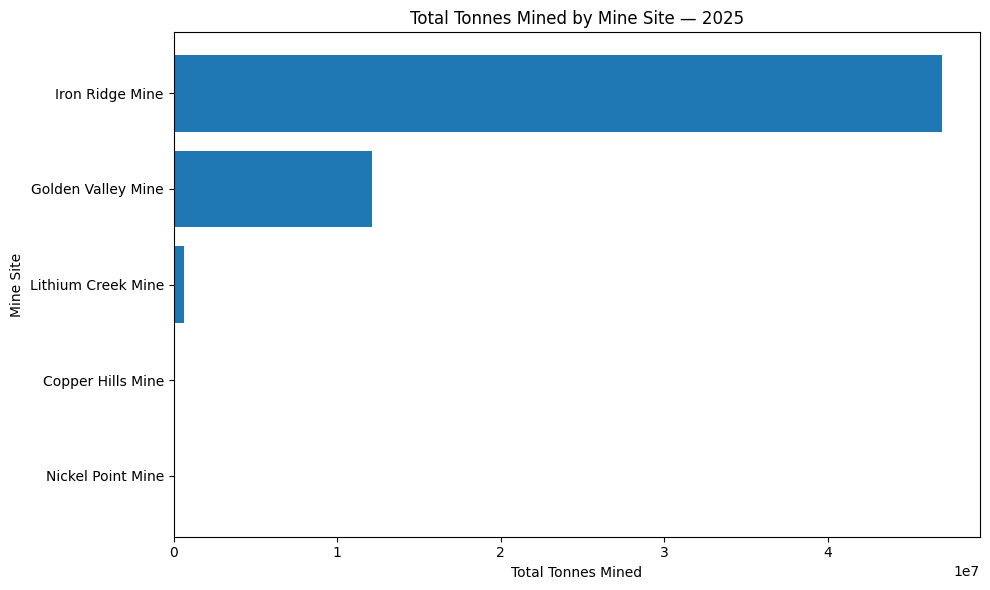

In [10]:
# Sort sites by total tonnes mined
plot_df = site_profile.sort_values(
    "total_tonnes_mined",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["site_name"],
    plot_df["total_tonnes_mined"]
)

plt.title("Total Tonnes Mined by Mine Site — 2025")
plt.xlabel("Total Tonnes Mined")
plt.ylabel("Mine Site")
plt.tight_layout()
plt.show()

**Interpretasi grafik**

- Iron Ridge Mine mendominasi volume produksi tahunan, diikuti Golden Valley Mine.
- Lithium Creek Mine dan Copper Hills Mine menghasilkan volume jauh lebih kecil.
- Nickel Point Mine tidak menghasilkan tonase selama periode data.

### Production against annual target
*(Analisis tambahan.)* Membandingkan produksi 2025 dengan `annual_target_tonnes`, rata-rata `plan_adherence_pct`, dan `recovery_rate` terhadap targetnya. Kolom-kolom ini belum dipakai pada analisis sebelumnya.

,site_name,commodity,total_tonnes_mined,annual_target_tonnes,target_attainment_pct,avg_plan_adherence_pct,avg_recovery_rate_pct,target_recovery_rate_pct,recovery_gap_pts
0,Iron Ridge Mine,Iron Ore,46935488,50000000,93.9,93.8,97.0,98.0,-1.0
1,Golden Valley Mine,Gold,12099285,13000000,93.1,93.0,90.1,91.0,-0.9
2,Lithium Creek Mine,Lithium,653542,700000,93.4,93.2,69.3,70.0,-0.7
3,Copper Hills Mine,Copper,18496,20000,92.5,92.1,87.0,88.0,-1.0
4,Nickel Point Mine,Nickel,0,0,NaN,0.0,0.0,0.0,0.0


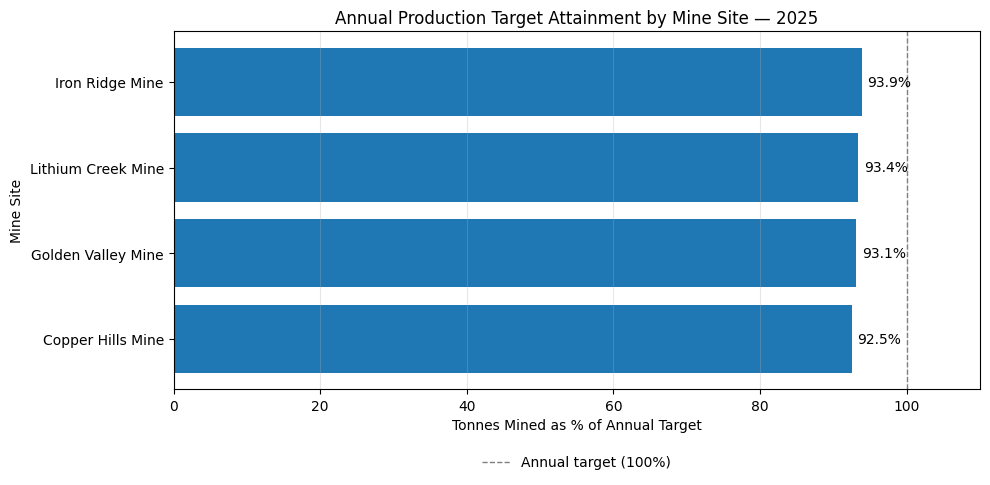

In [11]:
target_comparison = pd.read_sql_query("""
    SELECT
        p.site_name,
        p.commodity,
        SUM(p.tonnes_mined) AS total_tonnes_mined,
        m.annual_target_tonnes,
        ROUND(SUM(p.tonnes_mined) * 100.0 / NULLIF(m.annual_target_tonnes, 0), 1)
            AS target_attainment_pct,
        ROUND(AVG(p.plan_adherence_pct), 1) AS avg_plan_adherence_pct,
        ROUND(AVG(p.recovery_rate), 1) AS avg_recovery_rate_pct,
        m.target_recovery_rate AS target_recovery_rate_pct
    FROM daily_production AS p
    INNER JOIN mine_sites AS m
        ON p.site_id = m.site_id
    GROUP BY p.site_id, p.site_name, p.commodity,
             m.annual_target_tonnes, m.target_recovery_rate
    ORDER BY total_tonnes_mined DESC
""", conn)

target_comparison["recovery_gap_pts"] = (
    target_comparison["avg_recovery_rate_pct"]
    - target_comparison["target_recovery_rate_pct"]
).round(1)

display(target_comparison)

# Chart: target attainment for producing sites
attainment_plot = (
    target_comparison
    .dropna(subset=["target_attainment_pct"])
    .sort_values("target_attainment_pct", ascending=True)
)

plt.figure(figsize=(10, 5))
bars = plt.barh(attainment_plot["site_name"], attainment_plot["target_attainment_pct"])
plt.bar_label(bars, fmt="%.1f%%", padding=4)
plt.axvline(100, linestyle="--", linewidth=1, color="gray", label="Annual target (100%)")
plt.title("Annual Production Target Attainment by Mine Site — 2025")
plt.xlabel("Tonnes Mined as % of Annual Target")
plt.ylabel("Mine Site")
plt.xlim(0, 110)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi target produksi**

- Keempat lokasi yang berproduksi mencapai sekitar 92,5%–93,9% dari target tahunan. Tidak ada yang mencapai 100%.
- Rata-rata `plan_adherence_pct` harian juga berada di kisaran 92%–94%, searah dengan pencapaian target tahunan.
- Rata-rata `recovery_rate` berada sekitar 0,7–1,0 poin persentase di bawah target di semua lokasi yang berproduksi.
- Copper Hills Mine mencapai 92,5% dari target 20.000 ton. Volume kecilnya sesuai dengan target lokasinya, sehingga biaya per ton yang tinggi (Section 5) perlu dibaca bersama fakta ini.

## 4. Monthly Production Trend Analysis

### Objective
Analyze monthly mining and processing volumes to identify production trends and changes throughout 2025.

### Key Questions
- How does monthly production vary over time?
- Are there months with higher or lower production?
- Do mining and processing volumes follow similar trends?

### Method
Aggregate daily production records by month and visualize total tonnes mined and processed using a line chart.

In [12]:
# Monthly production trend analysis

monthly_production = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', date) AS month,
        SUM(tonnes_mined) AS total_tonnes_mined,
        SUM(tonnes_processed) AS total_tonnes_processed
    FROM daily_production
    GROUP BY strftime('%Y-%m', date)
    ORDER BY month
""", conn)

display(monthly_production)

,month,total_tonnes_mined,total_tonnes_processed
0,2025-01,5158201,5054973
1,2025-02,4778147,4682525
2,2025-03,4966208,4866817
3,2025-04,4768002,4672578
4,2025-05,5123209,5020685
5,2025-06,4732655,4637941
6,2025-07,5177396,5073786
7,2025-08,5196577,5092583
8,2025-09,4783778,4688041
9,2025-10,5086678,4984882


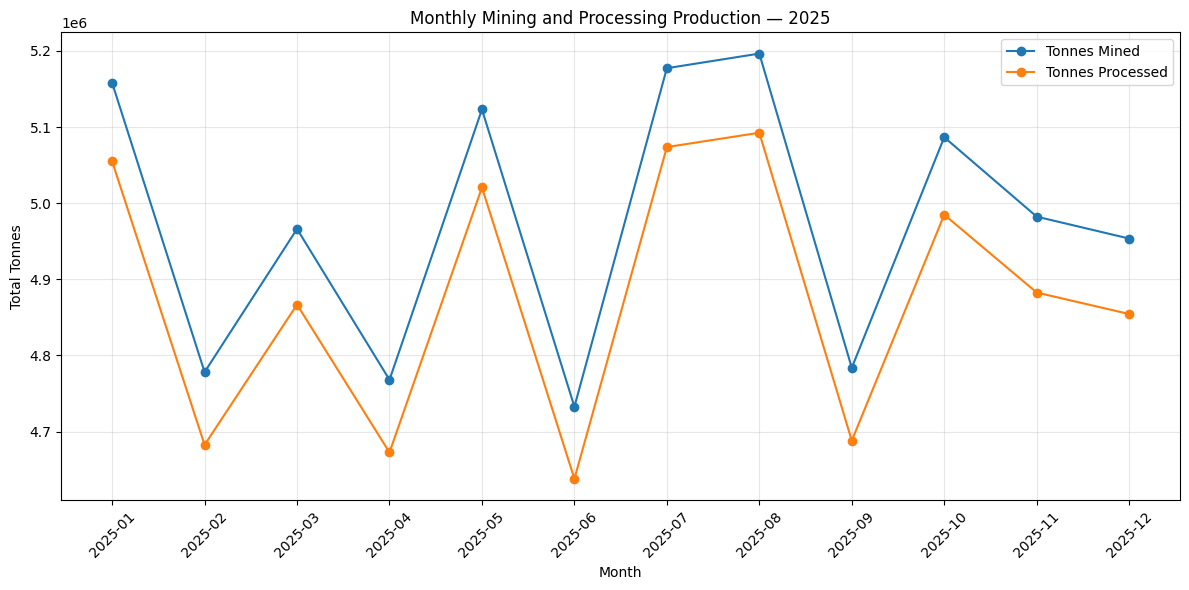

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_production["month"],
    monthly_production["total_tonnes_mined"],
    marker="o",
    label="Tonnes Mined"
)

plt.plot(
    monthly_production["month"],
    monthly_production["total_tonnes_processed"],
    marker="o",
    label="Tonnes Processed"
)

plt.title("Monthly Mining and Processing Production — 2025")
plt.xlabel("Month")
plt.ylabel("Total Tonnes")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi grafik produksi bulanan**

- Produksi material yang ditambang tertinggi terjadi pada Agustus, dengan Juli dan Agustus sebagai periode produksi tinggi.
- Produksi terendah terjadi pada Juni untuk kedua metrik.
- Produksi naik-turun dari bulan ke bulan dan tidak meningkat secara konsisten.
- Tonnes mined selalu lebih tinggi daripada tonnes processed pada setiap bulan. Penyebab selisih ini perlu dianalisis lebih lanjut.

### Monthly mined–processed gap
Membandingkan perubahan volume material yang ditambang dengan volume yang diproses sepanjang tahun.

In [14]:
# Calculate the monthly mined–processed gap

monthly_production["mined_processed_gap"] = (
    monthly_production["total_tonnes_mined"]
    - monthly_production["total_tonnes_processed"]
)

monthly_production["gap_percentage"] = (
    monthly_production["mined_processed_gap"]
    / monthly_production["total_tonnes_mined"].replace(0, float("nan"))
    * 100
).round(2)

display(monthly_production)

,month,total_tonnes_mined,total_tonnes_processed,mined_processed_gap,gap_percentage
0,2025-01,5158201,5054973,103228,2.0
1,2025-02,4778147,4682525,95622,2.0
2,2025-03,4966208,4866817,99391,2.0
3,2025-04,4768002,4672578,95424,2.0
4,2025-05,5123209,5020685,102524,2.0
5,2025-06,4732655,4637941,94714,2.0
6,2025-07,5177396,5073786,103610,2.0
7,2025-08,5196577,5092583,103994,2.0
8,2025-09,4783778,4688041,95737,2.0
9,2025-10,5086678,4984882,101796,2.0


**Interpretasi mined–processed gap**

- Selisih terbesar: Agustus 2025 (103.994 ton), diikuti Juli 2025 (103.610 ton). Selisih terkecil: Juni 2025 (94.714 ton).
- Persentase selisih tampil 2,0% pada semua bulan setelah pembulatan dua desimal.
- Material yang diproses setiap bulan sekitar 98% dari yang ditambang. Selisih ini belum tentu berarti kehilangan material, karena faktor operasional atau perbedaan waktu pencatatan belum diperiksa.

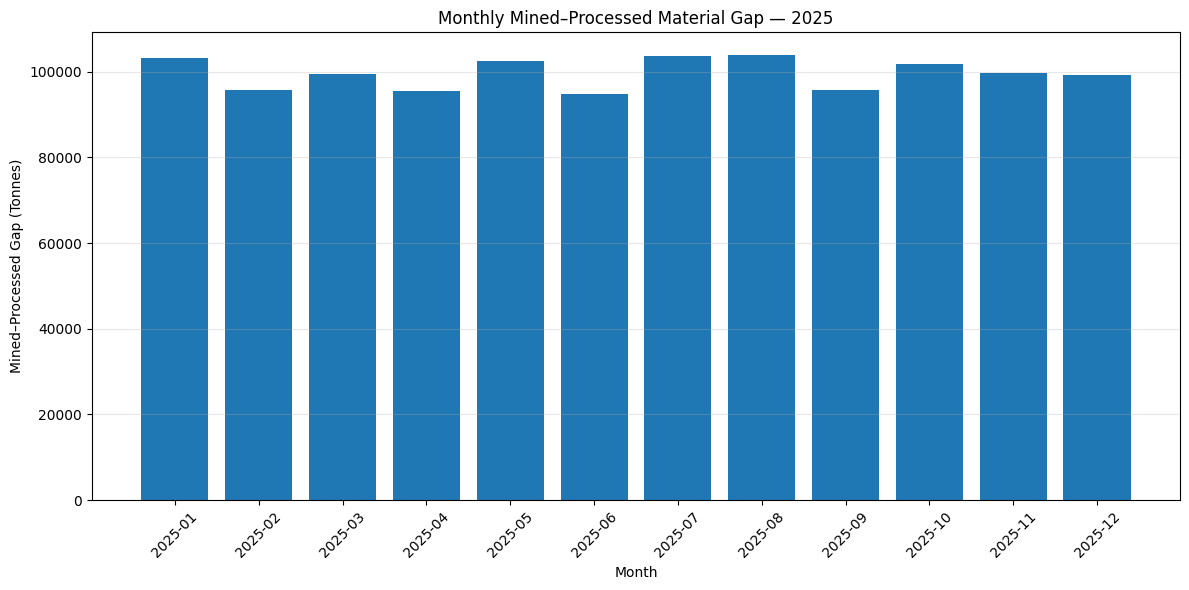

In [15]:
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_production["month"],
    monthly_production["mined_processed_gap"]
)

plt.title("Monthly Mined–Processed Material Gap — 2025")
plt.xlabel("Month")
plt.ylabel("Mined–Processed Gap (Tonnes)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly production per day
*(Analisis tambahan.)* Total bulanan dipengaruhi jumlah hari dalam bulan (28 hingga 31 hari). Normalisasi per hari memperlihatkan laju produksi yang sebenarnya.

,month,total_tonnes_mined,days_in_month,mined_per_day
0,2025-01,5158201,31,166394.0
1,2025-02,4778147,28,170648.0
2,2025-03,4966208,31,160200.0
3,2025-04,4768002,30,158933.0
4,2025-05,5123209,31,165265.0
5,2025-06,4732655,30,157755.0
6,2025-07,5177396,31,167013.0
7,2025-08,5196577,31,167632.0
8,2025-09,4783778,30,159459.0
9,2025-10,5086678,31,164086.0


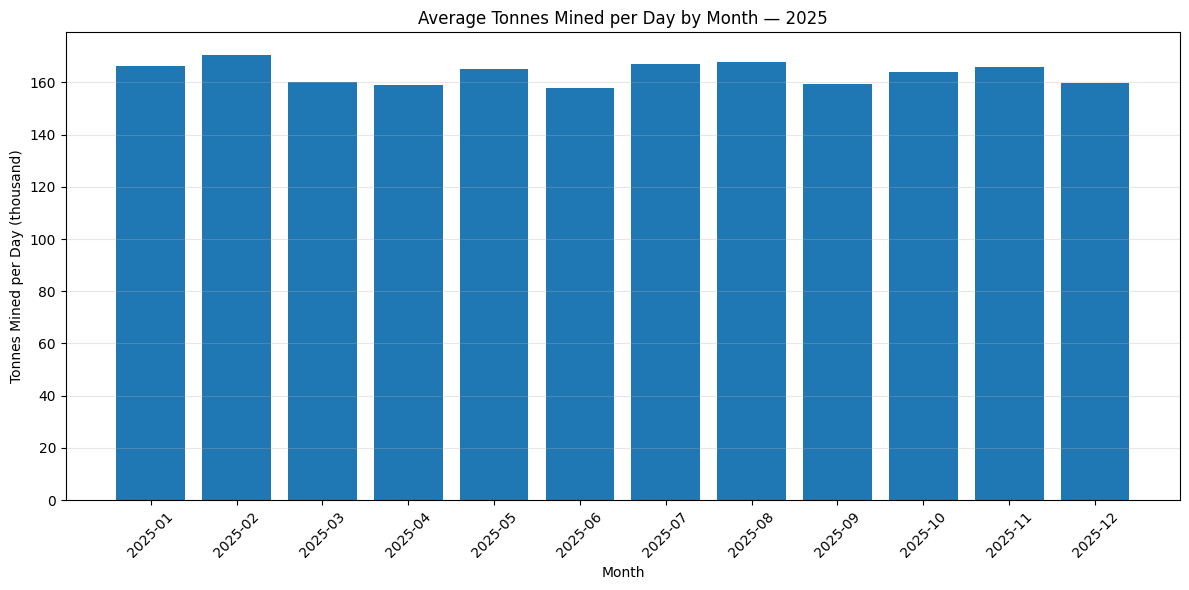

In [16]:
days_per_month = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', date) AS month,
        COUNT(DISTINCT date) AS days_in_month
    FROM daily_production
    GROUP BY strftime('%Y-%m', date)
""", conn)

monthly_rate = monthly_production[["month", "total_tonnes_mined"]].merge(
    days_per_month, on="month"
)
monthly_rate["mined_per_day"] = (
    monthly_rate["total_tonnes_mined"] / monthly_rate["days_in_month"]
).round(0)

display(monthly_rate)

plt.figure(figsize=(12, 6))
plt.bar(monthly_rate["month"], monthly_rate["mined_per_day"] / 1_000)
plt.title("Average Tonnes Mined per Day by Month — 2025")
plt.xlabel("Month")
plt.ylabel("Tonnes Mined per Day (thousand)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi produksi per hari**

- Setelah dinormalisasi, Februari memiliki laju produksi tertinggi, sekitar 170.648 ton/hari, meskipun total bulanannya bukan yang tertinggi karena hanya 28 hari.
- Juni tetap terendah, sekitar 157.755 ton/hari. Agustus, Juli, dan Januari berada di kelompok atas.
- Perbedaan total antar bulan sebagian disebabkan jumlah hari, sehingga perbandingan bulanan sebaiknya memakai laju per hari.

### Downtime impact on daily production
*(Analisis tambahan.)* `downtime_hours` pada `daily_production` belum dianalisis. Bagian ini membandingkan produksi pada hari dengan dan tanpa downtime, dan mengestimasi tonase yang hilang. Nilai estimasi memakai selisih rata-rata antara hari normal dan hari downtime.

In [17]:
daily_prod = pd.read_sql_query("""
    SELECT site_name, date, tonnes_mined, plan_adherence_pct, downtime_hours
    FROM daily_production
    WHERE status = 'Operational'
""", conn)

daily_prod["has_downtime"] = daily_prod["downtime_hours"] > 0

normal_days = (
    daily_prod[~daily_prod["has_downtime"]]
    .groupby("site_name")
    .agg(
        normal_days=("date", "count"),
        avg_tonnes_normal_day=("tonnes_mined", "mean")
    )
)

downtime_days = (
    daily_prod[daily_prod["has_downtime"]]
    .groupby("site_name")
    .agg(
        downtime_days=("date", "count"),
        total_downtime_hours=("downtime_hours", "sum"),
        avg_tonnes_downtime_day=("tonnes_mined", "mean")
    )
)

downtime_impact = normal_days.join(downtime_days)
downtime_impact["estimated_tonnes_lost"] = (
    downtime_impact["downtime_days"]
    * (downtime_impact["avg_tonnes_normal_day"] - downtime_impact["avg_tonnes_downtime_day"])
)
downtime_impact["estimated_loss_pct_of_mined"] = (
    downtime_impact["estimated_tonnes_lost"]
    / daily_prod.groupby("site_name")["tonnes_mined"].sum()
    * 100
)

display(downtime_impact.round(1).reset_index())

,site_name,normal_days,avg_tonnes_normal_day,downtime_days,total_downtime_hours,avg_tonnes_downtime_day,estimated_tonnes_lost,estimated_loss_pct_of_mined
0,Copper Hills Mine,357,51.5,8,134.4,14.9,292.8,1.6
1,Golden Valley Mine,357,33647.8,8,134.4,10876.8,182168.5,1.5
2,Iron Ridge Mine,357,130579.4,8,134.4,39829.9,725996.3,1.5
3,Lithium Creek Mine,355,1822.4,10,153.6,659.3,11630.9,1.8


**Interpretasi dampak downtime**

- Setiap lokasi yang berproduksi hanya mengalami downtime pada 8–10 hari dalam setahun, tetapi produksi pada hari-hari tersebut turun tajam. Pada Iron Ridge Mine, rata-rata produksi hari downtime sekitar 39.800 ton dibandingkan sekitar 130.600 ton pada hari normal.
- Estimasi tonase yang hilang berada di kisaran 1,5%–1,8% dari produksi tahunan masing-masing lokasi (sekitar 726 ribu ton di Iron Ridge Mine). Ini hanya menjelaskan sebagian kecil dari kekurangan sekitar 6%–7,5% terhadap target (Section 3).
- Kolom `weather_delay_hours` hanya terisi di Lithium Creek Mine (19 jam pada 2 hari).
- Pola tanggal downtime dibahas di Section 9.5.

## 5. Operational Cost Analysis

### Objective
Explore operational expenditure across mine sites and understand the distribution of costs across different cost categories.

### Key Questions
- Which mine sites incur the highest total operational costs?
- Which cost categories contribute most to expenditure?
- How does operational cost vary over time?
- Which sites have the highest and lowest cost per tonne mined?

### Method
Inspect the schema of the `daily_costs` table, aggregate expenditure by mine site and cost category, and compare it with production.

In [18]:
# Inspect the daily_costs table schema

cost_schema = pd.read_sql_query(
    'PRAGMA table_info("daily_costs")',
    conn
)

display(cost_schema[["name", "type"]])

,name,type
0,date,TEXT
1,site_id,TEXT
2,site_name,TEXT
3,commodity,TEXT
4,labor_cost_aud,REAL
5,equipment_cost_aud,REAL
6,fuel_cost_aud,REAL
7,maintenance_cost_aud,REAL
8,consumables_cost_aud,REAL
9,utilities_cost_aud,REAL


### Total cost by mine site

Semua komponen biaya menggunakan mata uang AUD (Australian Dollar):

| Kolom | Arti |
|---|---|
| `labor_cost_aud` | Biaya tenaga kerja |
| `equipment_cost_aud` | Biaya peralatan |
| `fuel_cost_aud` | Biaya bahan bakar |
| `maintenance_cost_aud` | Biaya pemeliharaan |
| `consumables_cost_aud` | Biaya bahan habis pakai |
| `utilities_cost_aud` | Biaya utilitas |
| `admin_cost_aud` | Biaya administrasi |
| `total_cost_aud` | Total biaya |

In [19]:
# Aggregate operational costs by mine site

site_costs = pd.read_sql_query("""
    SELECT
        site_id,
        site_name,
        COUNT(*) AS total_records,
        ROUND(SUM(total_cost_aud), 2) AS total_cost_aud,
        ROUND(AVG(total_cost_aud), 2) AS avg_daily_cost_aud,
        ROUND(SUM(labor_cost_aud), 2) AS labor_cost_aud,
        ROUND(SUM(equipment_cost_aud), 2) AS equipment_cost_aud,
        ROUND(SUM(fuel_cost_aud), 2) AS fuel_cost_aud,
        ROUND(SUM(maintenance_cost_aud), 2) AS maintenance_cost_aud,
        ROUND(SUM(consumables_cost_aud), 2) AS consumables_cost_aud,
        ROUND(SUM(utilities_cost_aud), 2) AS utilities_cost_aud,
        ROUND(SUM(admin_cost_aud), 2) AS admin_cost_aud
    FROM daily_costs
    GROUP BY site_id, site_name
    ORDER BY total_cost_aud DESC
""", conn)

display(site_costs)

,site_id,site_name,total_records,total_cost_aud,avg_daily_cost_aud,labor_cost_aud,equipment_cost_aud,fuel_cost_aud,maintenance_cost_aud,consumables_cost_aud,utilities_cost_aud,admin_cost_aud
0,IRON001,Iron Ridge Mine,365,1.269626e+09,3478427.24,5.078504e+08,3.554953e+08,2.285327e+08,1.015701e+08,50785037.70,12696259.35,12696259.35
1,GOLD001,Golden Valley Mine,365,9.709568e+08,2660155.66,3.883827e+08,2.718679e+08,1.747722e+08,7.767655e+07,38838272.80,9709568.21,9709568.21
2,LITH001,Lithium Creek Mine,365,4.174233e+08,1143625.40,1.669693e+08,1.168785e+08,7.513619e+07,3.339386e+07,16696930.83,4174232.71,4174232.71
3,COPP001,Copper Hills Mine,365,7.543240e+07,206664.10,3.017296e+07,2.112107e+07,1.357783e+07,6.034592e+06,3017295.82,754323.88,754323.88
4,NICK001,Nickel Point Mine,365,3.102500e+06,8500.00,1.825000e+06,0.000000e+00,0.000000e+00,7.300000e+05,0.00,365000.00,182500.00


**Interpretasi biaya operasional**

| Peringkat | Mine site | Total biaya (AUD) |
|---|---|---|
| 1 | Iron Ridge Mine | 1.269.626.000 |
| 2 | Golden Valley Mine | 970.956.800 |
| 3 | Lithium Creek Mine | 417.423.300 |
| 4 | Copper Hills Mine | 75.432.400 |
| 5 | Nickel Point Mine | 3.102.500 |

Angka dibulatkan untuk memudahkan pembacaan. Nilai lengkap tersedia pada output tabel.

- Iron Ridge Mine memiliki biaya total tertinggi sekaligus volume produksi tertinggi, diikuti Golden Valley Mine.
- Nickel Point Mine tetap mencatat biaya (sekitar A$8.500 per hari) meskipun tidak berproduksi.
- Total biaya saja belum cukup untuk menilai efisiensi, sehingga biaya perlu dibandingkan dengan volume produksi.

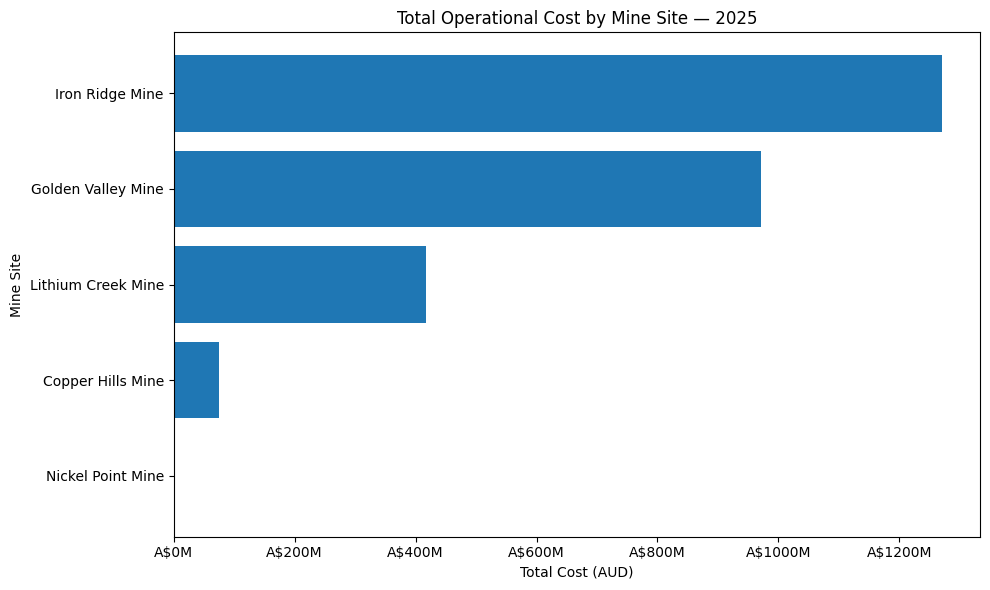

In [20]:
cost_plot = site_costs.sort_values(
    "total_cost_aud",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    cost_plot["site_name"],
    cost_plot["total_cost_aud"]
)

plt.title("Total Operational Cost by Mine Site — 2025")
plt.xlabel("Total Cost (AUD)")
plt.ylabel("Mine Site")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"A${x / 1_000_000:.0f}M")
)

plt.tight_layout()
plt.show()

### Operating cost per tonne by site

Biaya operasional per ton dihitung sebagai total biaya dibagi total tonnes mined. Nilainya tidak terdefinisi (`NaN`) untuk lokasi tanpa produksi, sehingga lokasi tersebut dikeluarkan dari peringkat dan dibaca terpisah.

In [21]:
# Aggregate annual production and cost by mine site
site_performance = pd.read_sql_query("""
    SELECT
        p.site_id,
        p.site_name,
        SUM(p.tonnes_mined) AS total_tonnes_mined,
        SUM(c.total_cost_aud) AS total_cost_aud
    FROM daily_production AS p
    INNER JOIN daily_costs AS c
        ON p.date = c.date
        AND p.site_id = c.site_id
    GROUP BY p.site_id, p.site_name
    ORDER BY total_tonnes_mined DESC
""", conn)

# Calculate cost per tonne only for sites with positive production
site_performance["cost_per_tonne_aud"] = (
    site_performance["total_cost_aud"]
    / site_performance["total_tonnes_mined"].replace(0, np.nan)
)

display(
    site_performance.style.format({
        "total_tonnes_mined": "{:,.0f}",
        "total_cost_aud": "A${:,.2f}",
        "cost_per_tonne_aud": "A${:,.2f}"
    })
)

,site_id,site_name,total_tonnes_mined,total_cost_aud,cost_per_tonne_aud
0,IRON001,Iron Ridge Mine,"46,935,488","A$1,269,625,942.36",A$27.05
1,GOLD001,Golden Valley Mine,"12,099,285","A$970,956,817.64",A$80.25
2,LITH001,Lithium Creek Mine,"653,542","A$417,423,270.49",A$638.71
3,COPP001,Copper Hills Mine,"18,496","A$75,432,396.80","A$4,078.31"
4,NICK001,Nickel Point Mine,0,"A$3,102,500.00",A$nan


**Interpretasi biaya per ton**

| Mine site | Ditambang (ton) | Biaya per ton (AUD/ton) |
|---|---|---|
| Iron Ridge Mine | 46.935.488 | 27,05 |
| Golden Valley Mine | 12.099.285 | 80,25 |
| Lithium Creek Mine | 653.542 | 638,71 |
| Copper Hills Mine | 18.496 | 4.078,31 |
| Nickel Point Mine | 0 | tidak terdefinisi |

- Iron Ridge Mine memiliki biaya per ton terendah, sekitar A$27,05/ton. Copper Hills Mine tertinggi, sekitar A$4.078,31/ton, atau sekitar 151 kali Iron Ridge.
- Volume produksi sangat memengaruhi metrik ini. Copper Hills hanya menambang 18.496 ton dengan total biaya A$75,43 juta, sehingga biaya tetap menghasilkan angka per ton yang tinggi.
- Perbandingan antar lokasi belum sepenuhnya setara karena komoditas, tipe tambang, dan skala berbeda. Angka ini menjadi sinyal untuk investigasi, belum bukti inefisiensi.
- Nickel Point Mine tidak ditampilkan karena produksinya nol, tetapi masih mencatat biaya operasional.

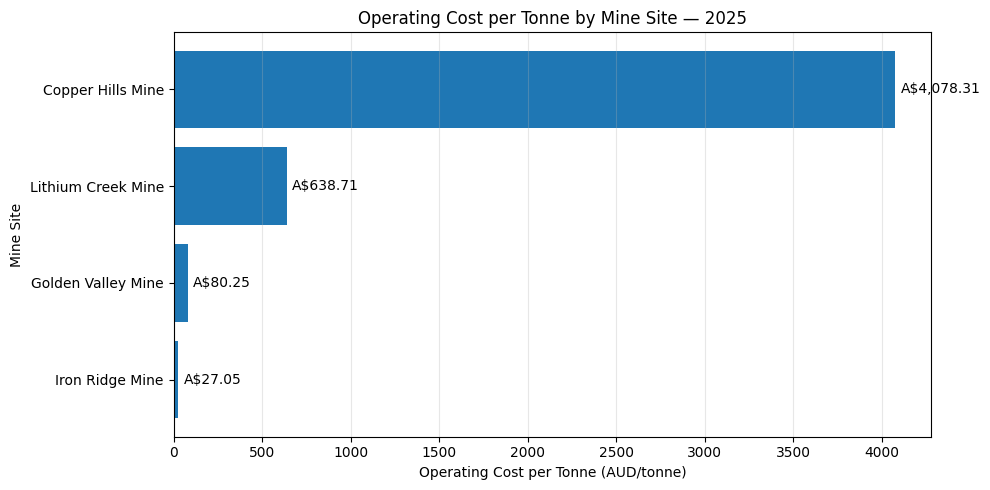

In [22]:
cost_efficiency = (
    site_performance
    .dropna(subset=["cost_per_tonne_aud"])
    .sort_values("cost_per_tonne_aud", ascending=True)
)

plt.figure(figsize=(10, 5))

bars = plt.barh(
    cost_efficiency["site_name"],
    cost_efficiency["cost_per_tonne_aud"]
)

plt.xlabel("Operating Cost per Tonne (AUD/tonne)")
plt.ylabel("Mine Site")
plt.title("Operating Cost per Tonne by Mine Site — 2025")
plt.grid(axis="x", alpha=0.3)

plt.bar_label(
    bars,
    labels=[
        f"A${value:,.2f}"
        for value in cost_efficiency["cost_per_tonne_aud"]
    ],
    padding=4
)

plt.tight_layout()
plt.show()

### Cost composition

In [23]:
# Analyse total cost composition across all mine sites

cost_components = [
    "labor_cost_aud",
    "equipment_cost_aud",
    "fuel_cost_aud",
    "maintenance_cost_aud",
    "consumables_cost_aud",
    "utilities_cost_aud",
    "admin_cost_aud"
]

component_totals = site_costs[cost_components].sum()

cost_composition = pd.DataFrame({
    "cost_component": component_totals.index,
    "total_cost_aud": component_totals.values
})

cost_composition["percentage_of_components"] = (
    cost_composition["total_cost_aud"]
    / cost_composition["total_cost_aud"].sum()
    * 100
).round(2)

cost_composition = cost_composition.sort_values(
    "total_cost_aud",
    ascending=False
)

display(cost_composition)

,cost_component,total_cost_aud,percentage_of_components
0,labor_cost_aud,1.095200e+09,40.02
1,equipment_cost_aud,7.653628e+08,27.97
2,fuel_cost_aud,4.920189e+08,17.98
3,maintenance_cost_aud,2.194051e+08,8.02
4,consumables_cost_aud,1.093375e+08,4.00
5,utilities_cost_aud,2.769938e+07,1.01
6,admin_cost_aud,2.751688e+07,1.01


**Interpretasi komposisi biaya**

| Komponen | Persentase |
|---|---|
| Labor | 40,02% |
| Equipment | 27,97% |
| Fuel | 17,98% |
| Maintenance | 8,02% |
| Consumables | 4,00% |
| Utilities | 1,01% |
| Administration | 1,01% |

Tenaga kerja, peralatan, dan bahan bakar secara gabungan menyumbang sekitar 85,97% dari total tujuh komponen biaya. Ketiganya paling relevan untuk diteliti lebih lanjut. Persentase ini menggambarkan dataset sintetis, bukan tolok ukur industri pertambangan.

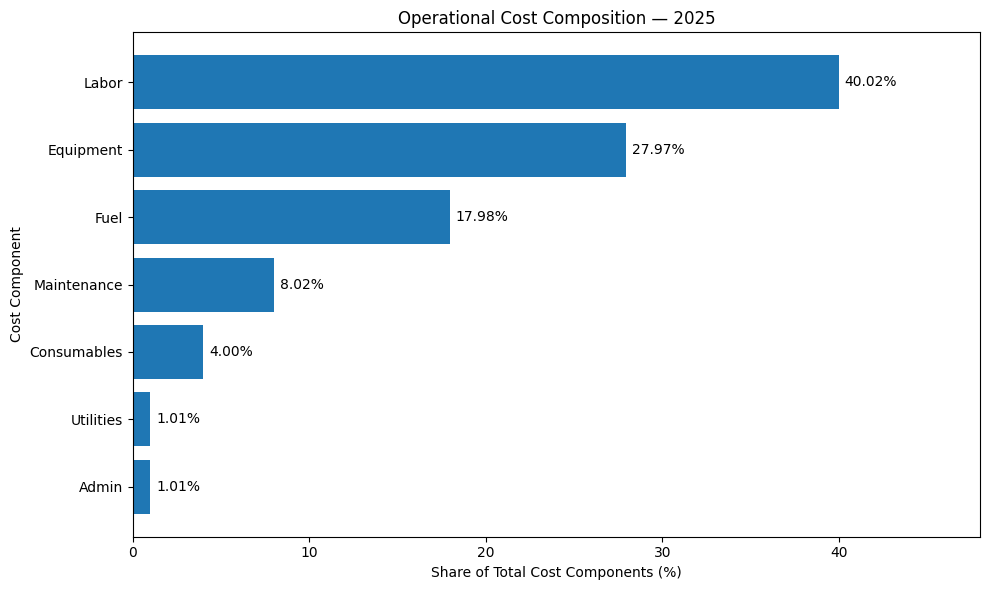

In [24]:
cost_plot = cost_composition.sort_values(
    "percentage_of_components",
    ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    cost_plot["cost_component"].str.replace(
        "_cost_aud", "", regex=False
    ).str.replace("_", " ").str.title(),
    cost_plot["percentage_of_components"]
)

plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

plt.title("Operational Cost Composition — 2025")
plt.xlabel("Share of Total Cost Components (%)")
plt.ylabel("Cost Component")
plt.xlim(0, 48)
plt.tight_layout()
plt.show()

### Monthly cost trend

In [25]:
# Monthly operational cost analysis

monthly_costs = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', date) AS month,
        SUM(total_cost_aud) AS total_cost_aud,
        SUM(labor_cost_aud) AS labor_cost_aud,
        SUM(equipment_cost_aud) AS equipment_cost_aud,
        SUM(fuel_cost_aud) AS fuel_cost_aud,
        SUM(maintenance_cost_aud) AS maintenance_cost_aud
    FROM daily_costs
    GROUP BY strftime('%Y-%m', date)
    ORDER BY month
""", conn)

display(monthly_costs)

,month,total_cost_aud,labor_cost_aud,equipment_cost_aud,fuel_cost_aud,maintenance_cost_aud
0,2025-01,2.369644e+08,94835373.69,66276261.58,42606168.12,18998074.75
1,2025-02,2.181239e+08,87294341.91,61008039.36,39219453.88,17486868.37
2,2025-03,2.265720e+08,90678412.69,63366388.85,40735535.70,18166682.53
3,2025-04,2.215668e+08,88674723.32,61967306.39,39836125.48,17764944.64
4,2025-05,2.356614e+08,94314140.73,65911398.49,42371613.39,18893828.19
5,2025-06,2.155752e+08,86278080.29,60289656.26,38757636.17,17285616.09
6,2025-07,2.362305e+08,94541802.38,66070761.77,42474061.07,18939360.44
7,2025-08,2.379276e+08,95220639.86,66545947.97,42779538.01,19075127.95
8,2025-09,2.181232e+08,87297299.23,61003109.47,39216284.73,17489459.77
9,2025-10,2.346739e+08,93919158.68,65634911.08,42193871.43,18814831.68


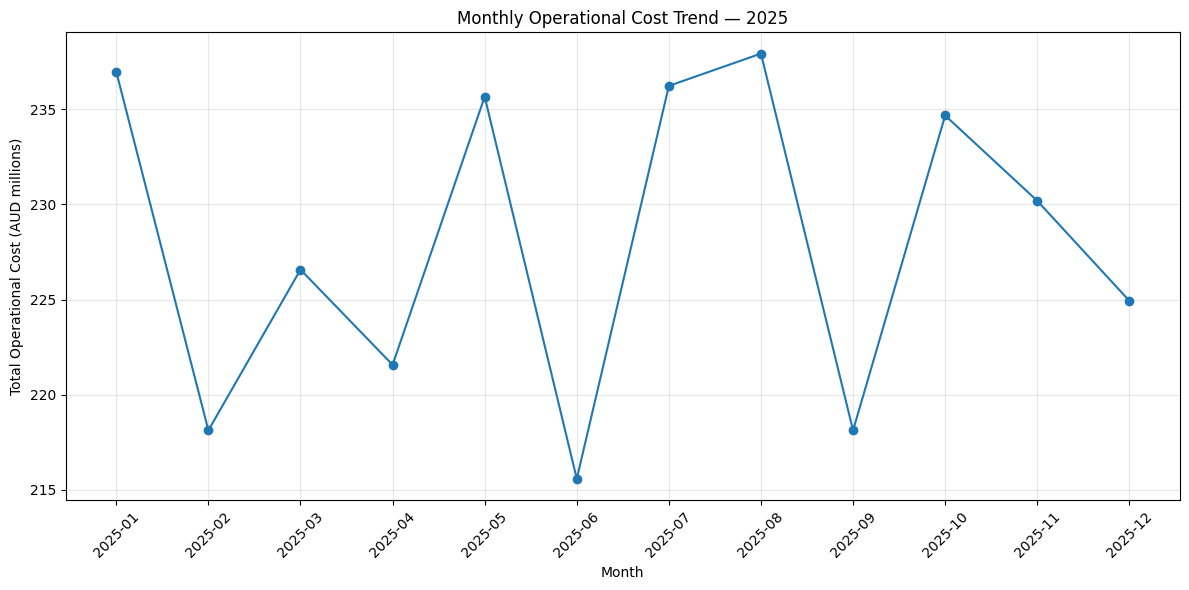

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_costs["month"],
    monthly_costs["total_cost_aud"] / 1_000_000,
    marker="o"
)

plt.title("Monthly Operational Cost Trend — 2025")
plt.xlabel("Month")
plt.ylabel("Total Operational Cost (AUD millions)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi tren biaya operasional 2025**

- Biaya tertinggi: Agustus 2025, sekitar AUD 237,9 juta.
- Biaya terendah: Juni 2025, sekitar AUD 215,6 juta.
- Biaya relatif tinggi: Januari, Mei, Juli, dan Agustus.
- Biaya berfluktuasi dari bulan ke bulan dan tidak naik secara konsisten sepanjang tahun.

### Monthly production vs operational cost

In [27]:
# Combine monthly production and cost data

monthly_operational = monthly_production.merge(
    monthly_costs[["month", "total_cost_aud"]],
    on="month",
    how="inner"
)

monthly_operational["cost_per_tonne_mined_aud"] = (
    monthly_operational["total_cost_aud"]
    / monthly_operational["total_tonnes_mined"]
).round(2)

display(
    monthly_operational[
        [
            "month",
            "total_tonnes_mined",
            "total_tonnes_processed",
            "total_cost_aud",
            "cost_per_tonne_mined_aud"
        ]
    ]
)

,month,total_tonnes_mined,total_tonnes_processed,total_cost_aud,cost_per_tonne_mined_aud
0,2025-01,5158201,5054973,2.369644e+08,45.94
1,2025-02,4778147,4682525,2.181239e+08,45.65
2,2025-03,4966208,4866817,2.265720e+08,45.62
3,2025-04,4768002,4672578,2.215668e+08,46.47
4,2025-05,5123209,5020685,2.356614e+08,46.00
5,2025-06,4732655,4637941,2.155752e+08,45.55
6,2025-07,5177396,5073786,2.362305e+08,45.63
7,2025-08,5196577,5092583,2.379276e+08,45.79
8,2025-09,4783778,4688041,2.181232e+08,45.60
9,2025-10,5086678,4984882,2.346739e+08,46.14


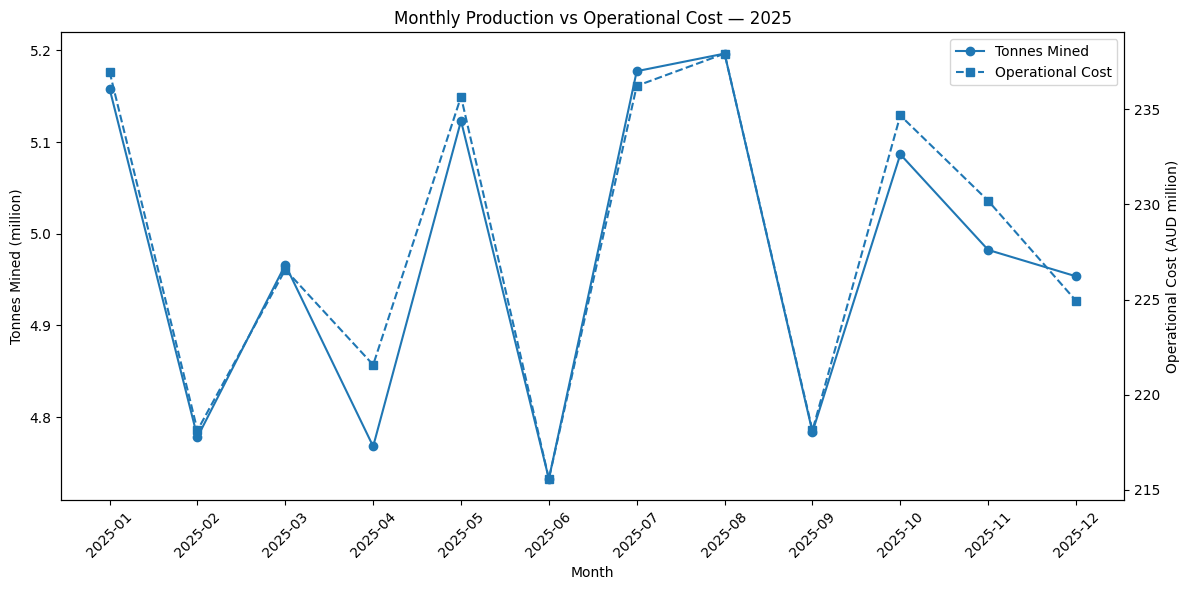

In [28]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Production volume
ax1.plot(
    monthly_operational["month"],
    monthly_operational["total_tonnes_mined"] / 1_000_000,
    marker="o",
    label="Tonnes Mined"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Tonnes Mined (million)")
ax1.tick_params(axis="x", rotation=45)

# Operational cost on a second axis
ax2 = ax1.twinx()

ax2.plot(
    monthly_operational["month"],
    monthly_operational["total_cost_aud"] / 1_000_000,
    marker="s",
    linestyle="--",
    label="Operational Cost"
)

ax2.set_ylabel("Operational Cost (AUD million)")

# Combined title and legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper right"
)

plt.title("Monthly Production vs Operational Cost — 2025")
fig.tight_layout()
plt.show()

**Interpretasi grafik**

- Produksi dan biaya cenderung bergerak searah. Ketika tonase turun, biaya bulanan juga turun, misalnya pada Juni dan September.
- Juli–Agustus menunjukkan volume produksi dan biaya yang relatif tinggi. Juni memiliki produksi dan biaya terendah.
- Pola ini menunjukkan kemungkinan hubungan antara skala produksi dan biaya operasional. Grafik saja belum membuktikan kekuatan hubungan atau sebab-akibat.

### Correlation between monthly production and operational cost

In [29]:
# Correlation between monthly production and operational cost

monthly_corr = monthly_operational[
    ["total_tonnes_mined", "total_cost_aud"]
].corr(method="pearson").iloc[0, 1]

print(
    "Pearson correlation between tonnes mined and operational cost:",
    round(monthly_corr, 3)
)

Pearson correlation between tonnes mined and operational cost: 0.982


In [30]:
# Monthly cost per tonne: how stable is it?
cost_per_tonne_range = (
    monthly_operational["cost_per_tonne_mined_aud"]
    .agg(["min", "mean", "max"])
    .round(2)
    .to_frame("monthly_cost_per_tonne_aud")
    .T
)

display(cost_per_tonne_range)

,min,mean,max
monthly_cost_per_tonne_aud,45.41,45.83,46.47


**Interpretasi korelasi**

Koefisien Pearson antara tonnes mined bulanan dan total biaya operasional adalah **+0,982**, hubungan linear positif yang sangat kuat.

- Bulan dengan tonase lebih tinggi cenderung memiliki biaya lebih tinggi, dan sebaliknya. Hasil ini konsisten dengan grafik sebelumnya.
- Biaya per ton bulanan sangat stabil, hanya sekitar A$45,4–46,5/ton. Artinya biaya bergerak hampir proporsional dengan tonase, sehingga korelasi yang tinggi wajar terjadi. Setelah dinormalisasi per hari, korelasinya masih sekitar 0,97.
- Korelasi tidak membuktikan sebab-akibat. Hasil ini berasal dari 12 observasi bulanan pada dataset sintetis, sehingga diperlakukan sebagai temuan eksploratif.
- Analisis lanjutan dapat menelaah komponen biaya individual dan perbedaan antar lokasi.

## 6. Equipment Performance Analysis

Menganalisis tabel `equipment_performance` untuk mengeksplorasi jam operasi, downtime, dan pola performa peralatan.

In [31]:
# Inspect equipment performance schema

equipment_schema = pd.read_sql_query(
    'PRAGMA table_info("equipment_performance")',
    conn
)

display(equipment_schema[["name", "type"]])

,name,type
0,date,TEXT
1,site_id,TEXT
2,equipment_id,TEXT
3,equipment_type,TEXT
4,model,TEXT
5,autonomous,INTEGER
6,available_hours,REAL
7,operating_hours,REAL
8,idle_hours,REAL
9,maintenance_hours,REAL


### Equipment performance summary

| Kolom | Arti |
|---|---|
| `number_of_equipment` | Jumlah unit peralatan yang tercatat untuk setiap jenis |
| `avg_availability_pct` | Rata-rata persentase waktu peralatan tersedia |
| `avg_utilization_pct` | Rata-rata persentase penggunaan peralatan |
| `avg_oee_pct` | Rata-rata Overall Equipment Effectiveness |
| `total_breakdown_hours` | Total jam kerusakan yang tercatat |
| `total_maintenance_cost_aud` | Total biaya perawatan dalam dolar Australia |

In [32]:
equipment_summary = pd.read_sql_query("""
    SELECT
        equipment_type,
        COUNT(DISTINCT equipment_id) AS number_of_equipment,
        COUNT(*) AS total_records,
        ROUND(AVG(available_hours), 2) AS avg_available_hours,
        ROUND(AVG(operating_hours), 2) AS avg_operating_hours,
        ROUND(AVG(availability_pct), 2) AS avg_availability_pct,
        ROUND(AVG(utilization_pct), 2) AS avg_utilization_pct,
        ROUND(AVG(oee_pct), 2) AS avg_oee_pct,
        ROUND(SUM(breakdown_hours), 2) AS total_breakdown_hours,
        ROUND(SUM(maintenance_cost_aud), 2) AS total_maintenance_cost_aud
    FROM equipment_performance
    GROUP BY equipment_type
    ORDER BY avg_oee_pct DESC
""", conn)

display(equipment_summary)

,equipment_type,number_of_equipment,total_records,avg_available_hours,avg_operating_hours,avg_availability_pct,avg_utilization_pct,avg_oee_pct,total_breakdown_hours,total_maintenance_cost_aud
0,Haul Truck,8,2920,23.63,20.21,98.46,85.55,84.23,370.0,7362224.01
1,Excavator,5,1825,23.58,19.29,98.23,81.82,80.38,306.3,5099111.30
2,Dozer,4,1460,23.60,17.72,98.34,75.07,73.83,222.8,4023670.09
3,LHD Loader,3,1095,23.54,16.47,98.10,69.97,68.63,201.3,3053753.38
4,Jumbo Drill,2,730,23.62,11.89,98.40,50.35,49.55,103.4,1956990.44


**Interpretasi hasil**

| Jenis peralatan | Jumlah unit | Availability | Utilization | OEE |
|---|---|---|---|---|
| Haul Truck | 8 | 98,46% | 85,55% | 84,23% |
| Excavator | 5 | 98,23% | 81,82% | 80,38% |
| Dozer | 4 | 98,34% | 75,07% | 73,83% |
| LHD Loader | 3 | 98,10% | 69,97% | 68,63% |
| Jumbo Drill | 2 | 98,40% | 50,35% | 49,55% |

- **Haul Truck** memiliki OEE tertinggi (84,23%) dan utilization tertinggi (85,55%).
- **Jumbo Drill** memiliki OEE terendah (49,55%) meskipun availability-nya 98,40%. Peralatan sering tersedia, tetapi tidak banyak digunakan.
- Availability semua jenis peralatan berada di sekitar 98%, sedangkan utilization dan OEE berbeda jauh. Availability saja tidak menjelaskan perbedaan efektivitas.
- **Biaya perawatan:** Haul Truck memiliki total terbesar, sekitar A$7,36 juta (A$7.362.224,01), tetapi juga memiliki unit terbanyak (delapan). Total yang tinggi belum berarti perawatannya tidak efisien.

### OEE by equipment type

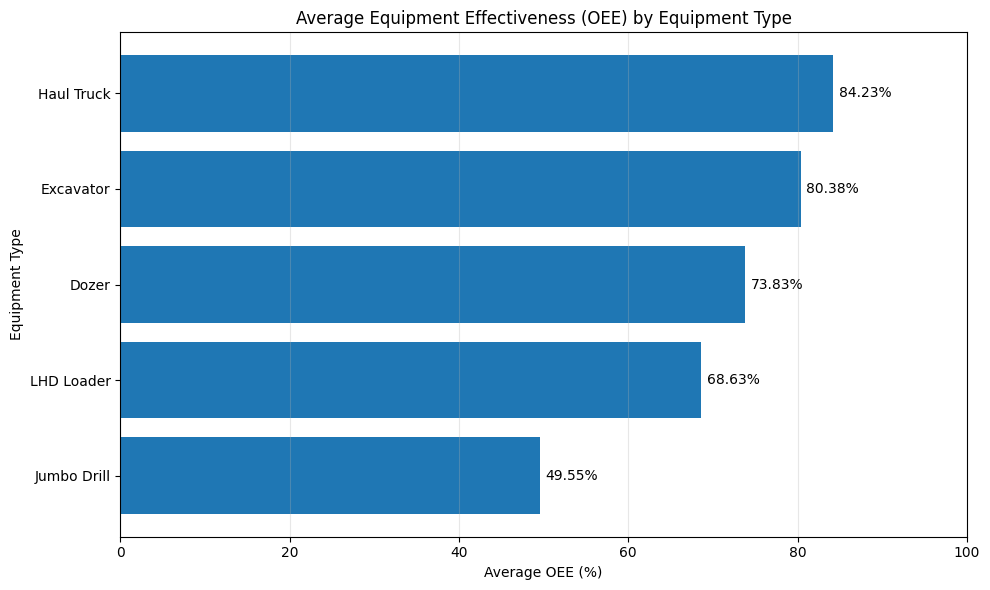

In [33]:
equipment_plot = equipment_summary.sort_values(
    "avg_oee_pct", ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    equipment_plot["equipment_type"],
    equipment_plot["avg_oee_pct"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.title("Average Equipment Effectiveness (OEE) by Equipment Type")
plt.xlabel("Average OEE (%)")
plt.ylabel("Equipment Type")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi grafik**

- **Haul Truck (84,23%)** adalah OEE tertinggi dan menjadi pembanding awal.
- **Jumbo Drill (49,55%)** terendah, selisih 34,68 poin persentase dari Haul Truck. Ini layak diteliti lebih lanjut, tetapi belum membuktikan kerusakan atau penyebab tertentu.
- Availability sekitar 98% pada semua jenis, tetapi OEE berkisar 49,55%–84,23%. Hubungan OEE dengan utilisasi, jam kerusakan, dan biaya perawatan diperiksa berikutnya.

### OEE, utilization, breakdown, and maintenance hours

In [34]:
equipment_relationship = pd.read_sql_query("""
    SELECT
        equipment_type,
        ROUND(AVG(oee_pct), 2) AS avg_oee_pct,
        ROUND(AVG(utilization_pct), 2) AS avg_utilization_pct,
        ROUND(AVG(breakdown_hours), 2) AS avg_breakdown_hours,
        ROUND(AVG(maintenance_hours), 2) AS avg_maintenance_hours,
        ROUND(AVG(availability_pct), 2) AS avg_availability_pct
    FROM equipment_performance
    GROUP BY equipment_type
    ORDER BY avg_oee_pct ASC
""", conn)

display(equipment_relationship)

,equipment_type,avg_oee_pct,avg_utilization_pct,avg_breakdown_hours,avg_maintenance_hours,avg_availability_pct
0,Jumbo Drill,49.55,50.35,0.14,0.24,98.40
1,LHD Loader,68.63,69.97,0.18,0.27,98.10
2,Dozer,73.83,75.07,0.15,0.25,98.34
3,Excavator,80.38,81.82,0.17,0.26,98.23
4,Haul Truck,84.23,85.55,0.13,0.24,98.46


**Hasil hubungan OEE dan breakdown**

- Jumbo Drill memiliki OEE dan utilization terendah, tetapi rata-rata breakdown-nya bukan yang tertinggi.
- LHD Loader memiliki rata-rata breakdown tertinggi (0,18 jam per catatan), tetapi bukan OEE terendah.
- Haul Truck memiliki OEE tertinggi dan rata-rata breakdown terendah (0,13 jam per catatan).

### Breakdown hours vs OEE (record level)

Correlation matrix:


,breakdown_hours,oee_pct,utilization_pct
breakdown_hours,1.000,-0.261,-0.000
oee_pct,-0.261,1.000,0.934
utilization_pct,-0.000,0.934,1.000


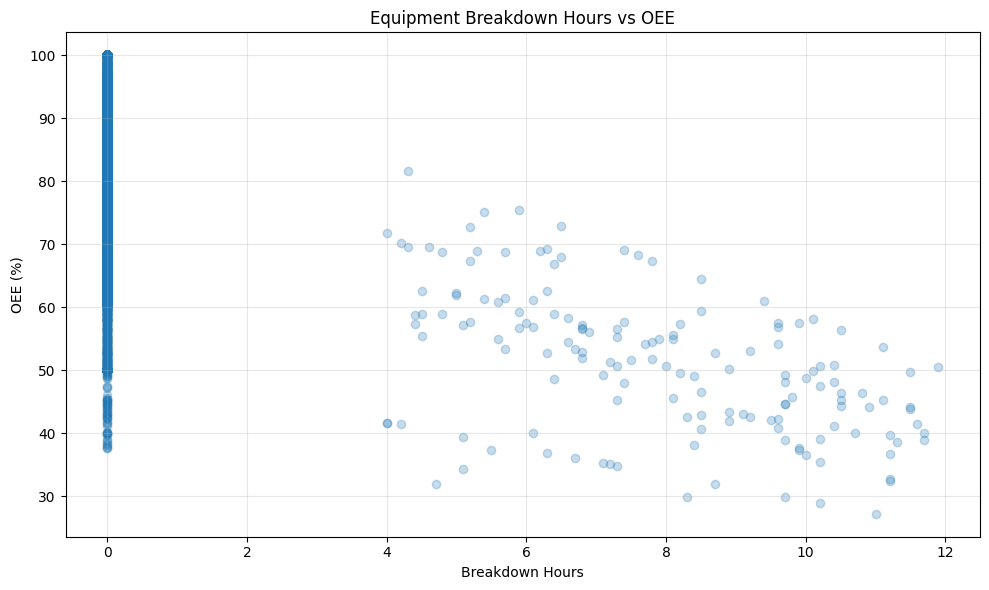

In [35]:
# Load individual equipment records
equipment_detail = pd.read_sql_query("""
    SELECT
        equipment_type,
        equipment_id,
        breakdown_hours,
        oee_pct,
        utilization_pct
    FROM equipment_performance
    WHERE breakdown_hours IS NOT NULL
      AND oee_pct IS NOT NULL
""", conn)

# Calculate correlation
equipment_corr = equipment_detail[
    ["breakdown_hours", "oee_pct", "utilization_pct"]
].corr()

print("Correlation matrix:")
display(equipment_corr.round(3))

# Scatter plot: breakdown hours vs OEE

plt.figure(figsize=(10, 6))
plt.scatter(
    equipment_detail["breakdown_hours"],
    equipment_detail["oee_pct"],
    alpha=0.25
)

plt.title("Equipment Breakdown Hours vs OEE")
plt.xlabel("Breakdown Hours")
plt.ylabel("OEE (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi korelasi**

| Pasangan variabel | Korelasi | Interpretasi |
|---|---|---|
| Breakdown hours dan OEE | −0,261 | Hubungan negatif lemah |
| Breakdown hours dan utilization | −0,000 | Hampir tidak ada hubungan linear |
| Utilization dan OEE | +0,934 | Hubungan positif sangat kuat |

- Jam kerusakan yang lebih tinggi cenderung berkaitan dengan OEE lebih rendah, tetapi hubungannya lemah.
- Korelasi utilization–OEE yang sangat tinggi bukan sekadar temuan empiris. Pengecekan di bawah menunjukkan OEE pada dataset ini sama dengan availability × utilization.
- Pada scatter plot, banyak titik menumpuk di sekitar nol jam kerusakan, sehingga pola keseluruhan kurang jelas. Ada kelompok titik dengan breakdown sekitar 4–12 jam yang cenderung memiliki OEE lebih rendah.

### Records with positive breakdown hours

In [36]:
# Compare records with zero vs positive breakdown hours
equipment_detail["breakdown_group"] = equipment_detail[
    "breakdown_hours"
].apply(
    lambda x: "Zero breakdown" if x == 0 else "Positive breakdown"
)

breakdown_comparison = (
    equipment_detail
    .groupby("breakdown_group")
    .agg(
        record_count=("oee_pct", "count"),
        avg_breakdown_hours=("breakdown_hours", "mean"),
        avg_oee_pct=("oee_pct", "mean"),
        avg_utilization_pct=("utilization_pct", "mean")
    )
    .round(2)
    .reset_index()
)

display(breakdown_comparison)

# Correlation among records with positive breakdown only
positive_breakdown = equipment_detail[
    equipment_detail["breakdown_hours"] > 0
]

print("Records with positive breakdown:", len(positive_breakdown))

print(
    "Correlation between breakdown hours and OEE "
    "among positive-breakdown records:",
    round(
        positive_breakdown["breakdown_hours"].corr(
            positive_breakdown["oee_pct"]
        ),
        3
    )
)

,breakdown_group,record_count,avg_breakdown_hours,avg_oee_pct,avg_utilization_pct
0,Positive breakdown,153,7.87,51.10,77.02
1,Zero breakdown,7877,0.00,76.67,77.48


Records with positive breakdown: 153
Correlation between breakdown hours and OEE among positive-breakdown records: -0.526


**Equipment Performance Insights**

- OEE rata-rata 76,67% pada catatan tanpa breakdown dan 51,10% pada catatan dengan breakdown positif, selisih 25,57 poin persentase.
- Utilization kedua kelompok hampir sama (77,48% dan 77,02%), sehingga utilization saja tidak menjelaskan perbedaan OEE ini.
- Pada 153 catatan dengan breakdown positif, korelasi breakdown hours dan OEE adalah −0,526 (hubungan negatif sedang).
- Breakdown jarang terjadi (153 dari 8.030 catatan, sekitar 1,9%), tetapi sangat menurunkan OEE pada hari terjadinya.

**Interpretasi:** Kejadian dan durasi breakdown berkaitan dengan efektivitas peralatan yang lebih rendah pada dataset ini. Penyebab lain dan hubungan kausal perlu dianalisis lebih lanjut.

**Keterbatasan:** Dataset bersifat sintetis dan temuan bersifat eksploratif untuk portofolio, bukan bukti kinerja tambang nyata.

### How OEE is built, and what drives it
*(Analisis tambahan.)* Dua pemeriksaan: (1) apakah OEE = availability × utilization, dan (2) apakah rata-rata OEE per jenis peralatan dipengaruhi lokasi dan status otonom (`autonomous`).

,records,mean_abs_diff_pts,max_abs_diff_pts
0,8030,0.0026,0.1186


,site_name,equipment_type,operation_mode,units,avg_oee_pct,avg_utilization_pct,avg_breakdown_hours_per_record
0,Golden Valley Mine,Dozer,Conventional,2,74.10,75.49,0.190
1,Iron Ridge Mine,Dozer,Conventional,1,74.07,75.11,0.105
2,Lithium Creek Mine,Dozer,Conventional,1,73.04,74.19,0.124
3,Lithium Creek Mine,Excavator,Conventional,1,80.86,82.13,0.141
4,Golden Valley Mine,Excavator,Conventional,2,80.33,81.93,0.197
5,Iron Ridge Mine,Excavator,Conventional,2,80.20,81.57,0.152
6,Iron Ridge Mine,Haul Truck,Autonomous,3,91.64,93.17,0.151
7,Lithium Creek Mine,Haul Truck,Conventional,2,81.17,82.39,0.101
8,Golden Valley Mine,Haul Truck,Conventional,3,78.86,80.05,0.119
9,Copper Hills Mine,Jumbo Drill,Conventional,2,49.55,50.35,0.142


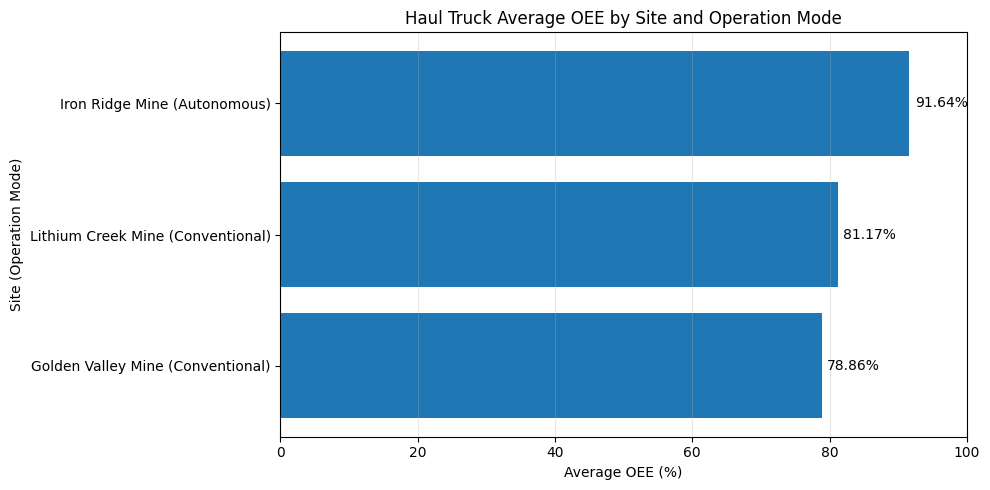

In [37]:
# 1) Is OEE simply availability x utilization?
oee_check = pd.read_sql_query("""
    SELECT
        COUNT(*) AS records,
        ROUND(AVG(ABS(oee_pct - availability_pct * utilization_pct / 100.0)), 4) AS mean_abs_diff_pts,
        ROUND(MAX(ABS(oee_pct - availability_pct * utilization_pct / 100.0)), 4) AS max_abs_diff_pts
    FROM equipment_performance
""", conn)

display(oee_check)

# 2) Equipment type by site, and conventional vs autonomous haul trucks
equipment_site_type = pd.read_sql_query("""
    SELECT
        s.site_name,
        e.equipment_type,
        CASE WHEN e.autonomous = 1 THEN 'Autonomous' ELSE 'Conventional' END AS operation_mode,
        COUNT(DISTINCT e.equipment_id) AS units,
        ROUND(AVG(e.oee_pct), 2) AS avg_oee_pct,
        ROUND(AVG(e.utilization_pct), 2) AS avg_utilization_pct,
        ROUND(AVG(e.breakdown_hours), 3) AS avg_breakdown_hours_per_record
    FROM equipment_performance AS e
    INNER JOIN mine_sites AS s
        ON e.site_id = s.site_id
    GROUP BY s.site_name, e.equipment_type, operation_mode
    ORDER BY e.equipment_type, avg_oee_pct DESC
""", conn)

display(equipment_site_type)

haul_trucks = equipment_site_type[equipment_site_type["equipment_type"] == "Haul Truck"].copy()
haul_trucks["label"] = haul_trucks["site_name"] + " (" + haul_trucks["operation_mode"] + ")"
haul_trucks = haul_trucks.sort_values("avg_oee_pct", ascending=True)

plt.figure(figsize=(10, 5))
bars = plt.barh(haul_trucks["label"], haul_trucks["avg_oee_pct"])
plt.bar_label(bars, fmt="%.2f%%", padding=4)
plt.title("Haul Truck Average OEE by Site and Operation Mode")
plt.xlabel("Average OEE (%)")
plt.ylabel("Site (Operation Mode)")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi faktor OEE**

- Selisih rata-rata antara OEE dan availability × utilization hanya sekitar 0,003 poin persentase (maksimum sekitar 0,12, setara pembulatan). OEE pada dataset ini dihitung dari availability dan utilization saja, tanpa komponen performance atau quality. Karena availability hampir konstan (~98%), OEE praktis mengikuti utilization, dan korelasi 0,934 memang diharapkan.
- OEE per jenis peralatan hampir identik di semua lokasi: Dozer sekitar 73%–74% dan Excavator sekitar 80%–81% di setiap lokasi. Perbedaan OEE antar jenis peralatan tampak lebih kuat daripada perbedaan antar lokasi.
- **Haul Truck:** tiga truk otonom (CAT 793F AHS) di Iron Ridge Mine mencapai OEE sekitar 91,6%, dibandingkan sekitar 79%–81% pada truk konvensional di Golden Valley dan Lithium Creek. Rata-rata breakdown per catatan pada truk otonom (0,151 jam) justru sedikit lebih tinggi daripada truk konvensional (0,101–0,119 jam), sedangkan utilization-nya jauh lebih tinggi (93,2% dibandingkan 80%–82%). Keunggulan OEE-nya berasal dari utilization, bukan dari keandalan.
- Jumbo Drill dan LHD Loader hanya ada di Copper Hills Mine, sehingga OEE rendah keduanya tidak bisa dipisahkan dari efek lokasi (tambang bawah tanah).
- Keterbatasan: hanya ada tiga unit otonom pada satu lokasi, sehingga perbandingan ini bersifat indikatif.

## 7. Equipment Maintenance Cost Analysis

### Objective
Evaluate maintenance expenditure and equipment breakdown patterns by equipment type.

### Business Questions
- Which equipment types account for the highest maintenance expenditure?
- Which equipment types experience the most breakdown hours?
- Do equipment types with lower OEE also show higher maintenance costs or breakdown hours?

The analysis is exploratory. Differences between equipment types do not by themselves establish that maintenance costs or breakdowns cause lower operational performance. Biaya perawatan di sini hanya mencakup 22 unit pada tabel peralatan (lihat Section 2).

| Kolom | Arti |
|---|---|
| `total_maintenance_cost_aud` | Total biaya perawatan yang tercatat untuk setiap jenis peralatan |
| `total_breakdown_hours` | Total jam kerusakan |
| `avg_oee_pct` | Rata-rata efektivitas peralatan |
| `number_of_equipment` | Jumlah unit berbeda yang tercatat (bukan jumlah catatan harian) |

In [38]:
# Aggregate maintenance and equipment performance by equipment type
maintenance_analysis = pd.read_sql_query("""
    SELECT
        equipment_type,
        COUNT(DISTINCT equipment_id) AS number_of_equipment,
        ROUND(AVG(oee_pct), 2) AS avg_oee_pct,
        ROUND(AVG(availability_pct), 2) AS avg_availability_pct,
        ROUND(AVG(utilization_pct), 2) AS avg_utilization_pct,
        ROUND(SUM(breakdown_hours), 2) AS total_breakdown_hours,
        ROUND(SUM(maintenance_hours), 2) AS total_maintenance_hours,
        ROUND(SUM(maintenance_cost_aud), 2) AS total_maintenance_cost_aud
    FROM equipment_performance
    GROUP BY equipment_type
    ORDER BY total_maintenance_cost_aud DESC
""", conn)

# Average maintenance cost per equipment unit (full year 2025)
maintenance_analysis["maintenance_cost_per_unit_aud"] = (
    maintenance_analysis["total_maintenance_cost_aud"]
    / maintenance_analysis["number_of_equipment"]
)

display(
    maintenance_analysis.style.format({
        "avg_oee_pct": "{:.2f}%",
        "avg_availability_pct": "{:.2f}%",
        "avg_utilization_pct": "{:.2f}%",
        "total_breakdown_hours": "{:,.2f}",
        "total_maintenance_hours": "{:,.2f}",
        "total_maintenance_cost_aud": "A${:,.2f}",
        "maintenance_cost_per_unit_aud": "A${:,.2f}"
    })
)

,equipment_type,number_of_equipment,avg_oee_pct,avg_availability_pct,avg_utilization_pct,total_breakdown_hours,total_maintenance_hours,total_maintenance_cost_aud,maintenance_cost_per_unit_aud
0,Haul Truck,8,84.23%,98.46%,85.55%,370.00,711.10,"A$7,362,224.01","A$920,278.00"
1,Excavator,5,80.38%,98.23%,81.82%,306.30,466.30,"A$5,099,111.30","A$1,019,822.26"
2,Dozer,4,73.83%,98.34%,75.07%,222.80,360.50,"A$4,023,670.09","A$1,005,917.52"
3,LHD Loader,3,68.63%,98.10%,69.97%,201.30,298.80,"A$3,053,753.38","A$1,017,917.79"
4,Jumbo Drill,2,49.55%,98.40%,50.35%,103.40,176.40,"A$1,956,990.44","A$978,495.22"


**Interpretasi hasil analisis**

| Jenis peralatan | Jumlah unit | Rata-rata OEE | Total jam kerusakan | Total biaya perawatan |
|---|---|---|---|---|
| Haul Truck | 8 | 84,23% | 370,0 jam | A$7,36 juta |
| Excavator | 5 | 80,38% | 306,3 jam | A$5,10 juta |
| Dozer | 4 | 73,83% | 222,8 jam | A$4,02 juta |
| LHD Loader | 3 | 68,63% | 201,3 jam | A$3,05 juta |
| Jumbo Drill | 2 | 49,55% | 103,4 jam | A$1,96 juta |

- Haul Truck memiliki total biaya perawatan tertinggi, tetapi juga unit terbanyak. Total yang tinggi belum berarti setiap unit lebih mahal dirawat.
- Jumbo Drill memiliki OEE terendah (49,55%), menjadikannya kandidat investigasi, tetapi penyebabnya belum bisa disimpulkan dari OEE saja.
- Availability semua jenis sekitar 98%, tetapi OEE berbeda jauh, sehingga ketersediaan saja tidak menggambarkan efektivitas operasional.
- Karena jumlah unit berbeda, perbandingan yang lebih adil memakai biaya perawatan rata-rata per unit.

### Average maintenance cost per unit

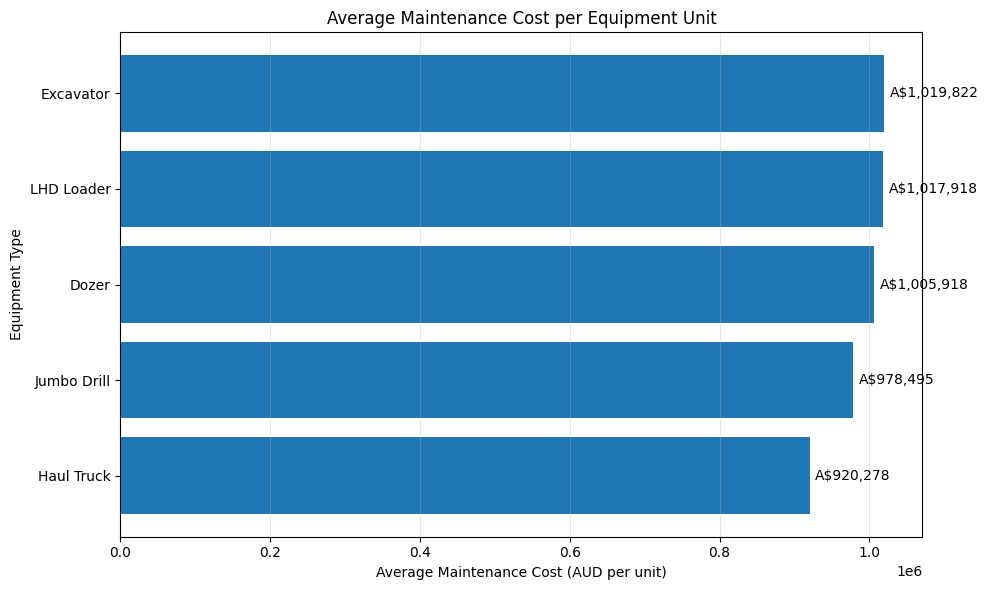

,equipment_type,number_of_equipment,total_maintenance_cost_aud,maintenance_cost_per_unit_aud
0,Haul Truck,8,7362224.01,920278.00
4,Jumbo Drill,2,1956990.44,978495.22
2,Dozer,4,4023670.09,1005917.52
3,LHD Loader,3,3053753.38,1017917.79
1,Excavator,5,5099111.30,1019822.26


In [39]:
cost_per_unit = maintenance_analysis.sort_values(
    "maintenance_cost_per_unit_aud",
    ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    cost_per_unit["equipment_type"],
    cost_per_unit["maintenance_cost_per_unit_aud"]
)

plt.bar_label(
    bars,
    labels=[
        f"A${value:,.0f}"
        for value in cost_per_unit["maintenance_cost_per_unit_aud"]
    ],
    padding=4
)

plt.title("Average Maintenance Cost per Equipment Unit")
plt.xlabel("Average Maintenance Cost (AUD per unit)")
plt.ylabel("Equipment Type")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(
    cost_per_unit[
        [
            "equipment_type",
            "number_of_equipment",
            "total_maintenance_cost_aud",
            "maintenance_cost_per_unit_aud"
        ]
    ].round(2)
)

**Interpretasi biaya perawatan per unit**

- Haul Truck memiliki total biaya perawatan tertinggi, tetapi biaya rata-rata per unit paling rendah (sekitar A$920 ribu). Excavator tertinggi (sekitar A$1,02 juta per unit).
- Selisih antar jenis peralatan relatif kecil (A$920 ribu hingga A$1,02 juta per unit), sehingga biaya per unit tidak membedakan kelompok peralatan sekuat OEE.
- Angka ini adalah biaya tercatat per unit selama 2025 pada dataset sintetis, bukan biaya dari operasi tambang nyata.

### Maintenance cost per unit vs OEE

**Objective:** Investigate the relationship between average maintenance cost per equipment unit and Overall Equipment Effectiveness (OEE).

**Analytical question:** Do equipment types with higher average maintenance costs demonstrate higher OEE?

**Approach:** Compare average maintenance cost per unit with average OEE across equipment types. Interpret the results as an association, not proof of causation.

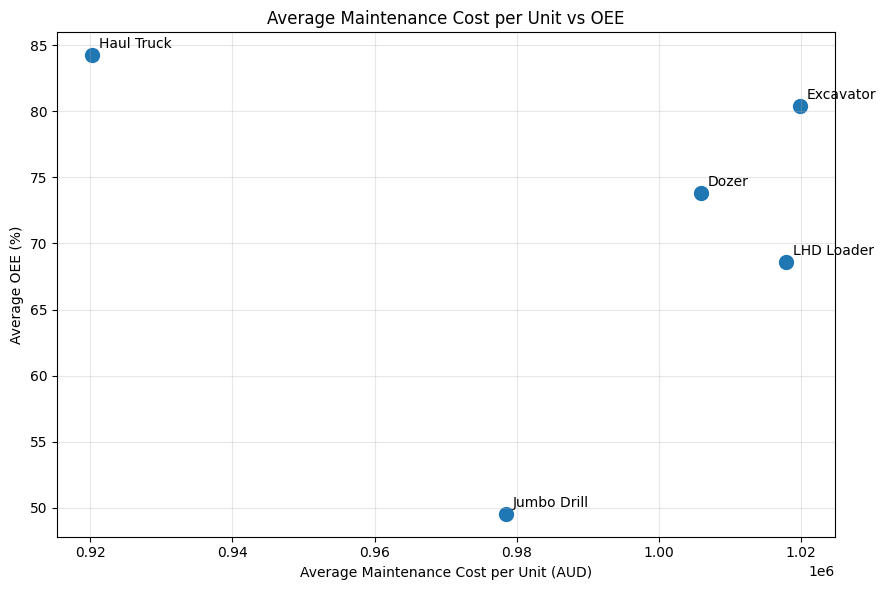

In [40]:
plt.figure(figsize=(9, 6))

plt.scatter(
    maintenance_analysis["maintenance_cost_per_unit_aud"],
    maintenance_analysis["avg_oee_pct"],
    s=100
)

for _, row in maintenance_analysis.iterrows():
    plt.annotate(
        row["equipment_type"],
        (
            row["maintenance_cost_per_unit_aud"],
            row["avg_oee_pct"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Average Maintenance Cost per Unit vs OEE")
plt.xlabel("Average Maintenance Cost per Unit (AUD)")
plt.ylabel("Average OEE (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi scatter plot**

- **Haul Truck:** OEE tertinggi (84,23%) dengan biaya perawatan per unit sekitar A$920 ribu, yang terendah dari lima jenis.
- **Jumbo Drill:** OEE hanya 49,55% meskipun biaya perawatannya sekitar A$978 ribu per unit. Perlu ditelusuri apakah downtime, utilisasi, atau faktor operasional lain berpengaruh.
- **Excavator:** biaya tertinggi per unit (sekitar A$1,02 juta) dengan OEE 80,38%. Biaya tinggi tidak otomatis berarti performa buruk.

Biaya perawatan yang lebih tinggi tidak selalu diikuti OEE yang lebih tinggi. Grafik ini hanya berisi lima titik, sehingga belum mendukung kesimpulan tentang korelasi kuat atau sebab-akibat.

### Breakdown and maintenance hours per unit

In [41]:
# Compare breakdown, maintenance hours, and OEE
equipment_diagnostic = maintenance_analysis[
    [
        "equipment_type",
        "avg_oee_pct",
        "avg_utilization_pct",
        "total_breakdown_hours",
        "total_maintenance_hours",
        "number_of_equipment"
    ]
].copy()

equipment_diagnostic["breakdown_hours_per_unit"] = (
    equipment_diagnostic["total_breakdown_hours"]
    / equipment_diagnostic["number_of_equipment"]
)

equipment_diagnostic["maintenance_hours_per_unit"] = (
    equipment_diagnostic["total_maintenance_hours"]
    / equipment_diagnostic["number_of_equipment"]
)

equipment_diagnostic = equipment_diagnostic.sort_values(
    "avg_oee_pct"
)

display(
    equipment_diagnostic[
        [
            "equipment_type",
            "avg_oee_pct",
            "avg_utilization_pct",
            "breakdown_hours_per_unit",
            "maintenance_hours_per_unit"
        ]
    ].round(2)
)

,equipment_type,avg_oee_pct,avg_utilization_pct,breakdown_hours_per_unit,maintenance_hours_per_unit
4,Jumbo Drill,49.55,50.35,51.70,88.20
3,LHD Loader,68.63,69.97,67.10,99.60
2,Dozer,73.83,75.07,55.70,90.12
1,Excavator,80.38,81.82,61.26,93.26
0,Haul Truck,84.23,85.55,46.25,88.89


**Temuan dari hasil analisis**

| Jenis peralatan | OEE | Utilisasi | Jam kerusakan/unit | Jam perawatan/unit |
|---|---|---|---|---|
| Jumbo Drill | 49,55% | 50,35% | 51,70 | 88,20 |
| LHD Loader | 68,63% | 69,97% | 67,10 | 99,60 |
| Dozer | 73,83% | 75,07% | 55,70 | 90,12 |
| Excavator | 80,38% | 81,82% | 61,26 | 93,26 |
| Haul Truck | 84,23% | 85,55% | 46,25 | 88,89 |

- Jumbo Drill memiliki OEE dan utilisasi terendah, menjadikannya kandidat utama untuk ditelusuri.
- LHD Loader memiliki jam kerusakan dan jam perawatan per unit tertinggi, tetapi OEE-nya bukan yang terendah.
- Haul Truck memiliki OEE tertinggi dan jam kerusakan per unit terendah.
- Jam perawatan yang tinggi tidak otomatis berarti performa buruk, karena perawatan terencana juga dapat meningkatkan keandalan.
- Hasil ini berasal dari dataset sintetis dan perbandingan agregat lima jenis peralatan, sehingga belum menunjukkan sebab-akibat.

### Chart: breakdown hours per unit vs equipment OEE

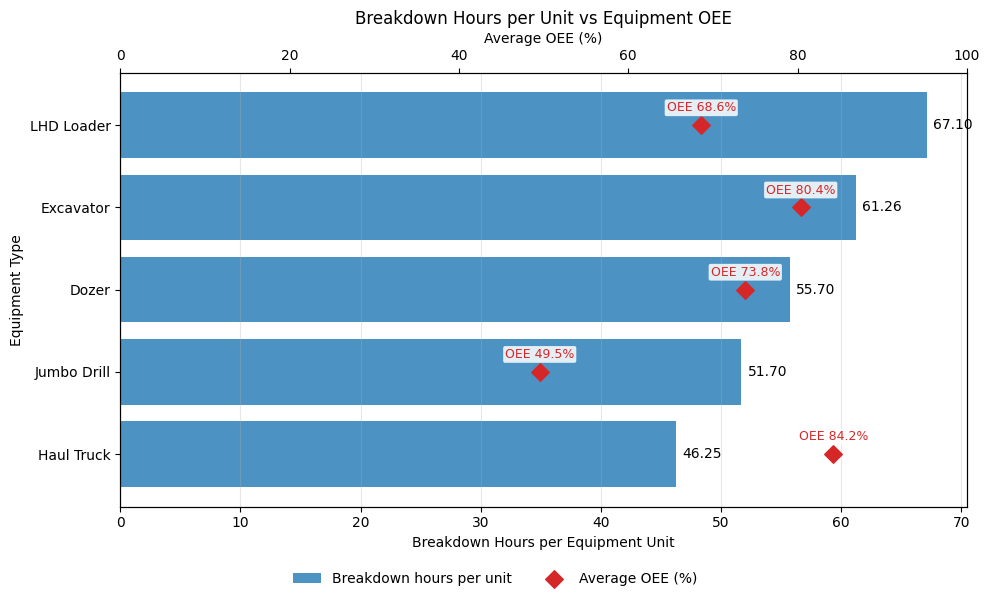

In [42]:
plot_data = equipment_diagnostic.sort_values(
    "breakdown_hours_per_unit",
    ascending=True
).reset_index(drop=True)

y = np.arange(len(plot_data))

fig, ax1 = plt.subplots(figsize=(10, 6))

bars = ax1.barh(
    y,
    plot_data["breakdown_hours_per_unit"],
    color="tab:blue",
    alpha=0.8,
    label="Breakdown hours per unit"
)

ax1.set_yticks(y)
ax1.set_yticklabels(plot_data["equipment_type"])
ax1.set_xlabel("Breakdown Hours per Equipment Unit")
ax1.set_ylabel("Equipment Type")
ax1.set_title("Breakdown Hours per Unit vs Equipment OEE")
ax1.grid(axis="x", alpha=0.3)

for bar, value in zip(bars, plot_data["breakdown_hours_per_unit"]):
    ax1.text(
        value + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center"
    )

# Average OEE on a secondary (top) axis
ax2 = ax1.twiny()
ax2.scatter(
    plot_data["avg_oee_pct"],
    y,
    marker="D",
    s=80,
    color="tab:red",
    zorder=3,
    label="Average OEE (%)"
)
ax2.set_xlim(0, 100)
ax2.set_xlabel("Average OEE (%)")

for x, yy in zip(plot_data["avg_oee_pct"], y):
    ax2.annotate(
        f"OEE {x:.1f}%",
        (x, yy),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        color="tab:red",
        fontsize=9,
        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)
    )

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=2, frameon=False)

plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Interpretasi grafik**

- LHD Loader: 67,10 jam/unit, tertinggi, sehingga layak diperiksa terkait pola kerusakan dan kebutuhan perawatan.
- Excavator: 61,26 jam/unit, posisi kedua.
- Haul Truck: 46,25 jam/unit, terendah, sejalan dengan OEE tertinggi (84,23%).
- Jumbo Drill: 51,70 jam/unit, tetapi OEE-nya paling rendah (49,55%). Jam kerusakan saja belum menjelaskan rendahnya OEE; utilisasi, performa operasional, dan kualitas data juga perlu dipertimbangkan.

## 8. Safety Performance Analysis

### Objective
Analyze workplace safety incidents to identify patterns in incident frequency, severity, and distribution across mine sites.

### Approach
- Inspect the structure of the safety incident tables.
- Review incident dates, categories, and severity fields.
- Summarize incident patterns using descriptive statistics.
- Visualize the findings to identify areas that may require further investigation.

**Note:** This dataset is synthetic. The findings are intended for exploratory analysis and portfolio demonstration.

In [43]:
# Inspect the safety-related table schemas

safety_tables = [
    "safety_incidents",
    "safety_metrics_summary"
]

for table_name in safety_tables:
    print(f"\n{'=' * 60}")
    print(f"TABLE: {table_name}")
    print("=" * 60)

    schema = pd.read_sql_query(
        f'PRAGMA table_info("{table_name}")',
        conn
    )

    display(schema[["name", "type"]])

    row_count = pd.read_sql_query(
        f'SELECT COUNT(*) AS total_rows FROM "{table_name}"',
        conn
    ).iloc[0]["total_rows"]

    print(f"Total records: {row_count:,}")


TABLE: safety_incidents


,name,type
0,incident_id,TEXT
1,date,TEXT
2,site_id,TEXT
3,site_name,TEXT
4,incident_type,TEXT
5,severity,TEXT
6,description,TEXT
7,days_lost,INTEGER
8,root_cause,TEXT
9,investigation_status,TEXT


Total records: 360

TABLE: safety_metrics_summary


,name,type
0,site_id,TEXT
1,site_name,TEXT
2,total_hours_worked,INTEGER
3,lti_count,INTEGER
4,mti_count,INTEGER
5,trifr,REAL
6,ltifr,REAL


Total records: 4


- `safety_incidents`: 360 catatan insiden dengan kolom tanggal, lokasi, jenis insiden, severity, days lost, root cause, dan status investigasi.
- `safety_metrics_summary`: 4 catatan ringkasan metrik keselamatan, termasuk total jam kerja, LTI, MTI, TRIFR, dan LTIFR. Nickel Point Mine tidak termasuk.

### Incident overview

In [44]:
# Safety incident overview

safety_overview = pd.read_sql_query("""
    SELECT
        COUNT(*) AS total_incidents,
        COUNT(DISTINCT site_id) AS sites_with_incidents,
        COUNT(DISTINCT incident_type) AS incident_types,
        SUM(days_lost) AS total_days_lost,
        ROUND(AVG(days_lost), 2) AS avg_days_lost,
        MIN(date) AS first_incident_date,
        MAX(date) AS last_incident_date
    FROM safety_incidents
""", conn)

display(safety_overview)

,total_incidents,sites_with_incidents,incident_types,total_days_lost,avg_days_lost,first_incident_date,last_incident_date
0,360,4,6,111,0.31,2025-01-01,2025-12-29


| Kolom | Arti |
|---|---|
| `total_incidents` | Jumlah seluruh catatan insiden |
| `sites_with_incidents` | Jumlah lokasi berbeda yang tercatat memiliki insiden |
| `incident_types` | Jumlah kategori insiden berbeda |
| `total_days_lost` | Akumulasi hari kerja yang hilang |
| `avg_days_lost` | Rata-rata hari kerja yang hilang per catatan |
| `first_incident_date`, `last_incident_date` | Rentang tanggal data |

### Incident distribution by severity

In [45]:
# Incident distribution by severity

severity_summary = pd.read_sql_query("""
    SELECT
        severity,
        COUNT(*) AS incident_count,
        ROUND(
            COUNT(*) * 100.0 /
            (SELECT COUNT(*) FROM safety_incidents),
            2
        ) AS percentage,
        SUM(days_lost) AS total_days_lost,
        ROUND(AVG(days_lost), 2) AS avg_days_lost
    FROM safety_incidents
    GROUP BY severity
    ORDER BY incident_count DESC
""", conn)

display(severity_summary)

,severity,incident_count,percentage,total_days_lost,avg_days_lost
0,Low,240,66.67,0,0.00
1,Medium,112,31.11,0,0.00
2,High,8,2.22,111,13.88


- 66,67% insiden berkategori Low dan 31,11% Medium.
- Ada 8 insiden High (2,22%), tetapi kategori ini menyumbang seluruh 111 hari kerja hilang yang tercatat. Rata-rata hari hilang untuk insiden High adalah 13,88 hari per insiden.
- Walaupun insiden High jumlahnya sedikit, dampaknya terhadap hari kerja yang hilang jauh lebih besar, sehingga analisis keselamatan tidak cukup hanya menghitung jumlah insiden.

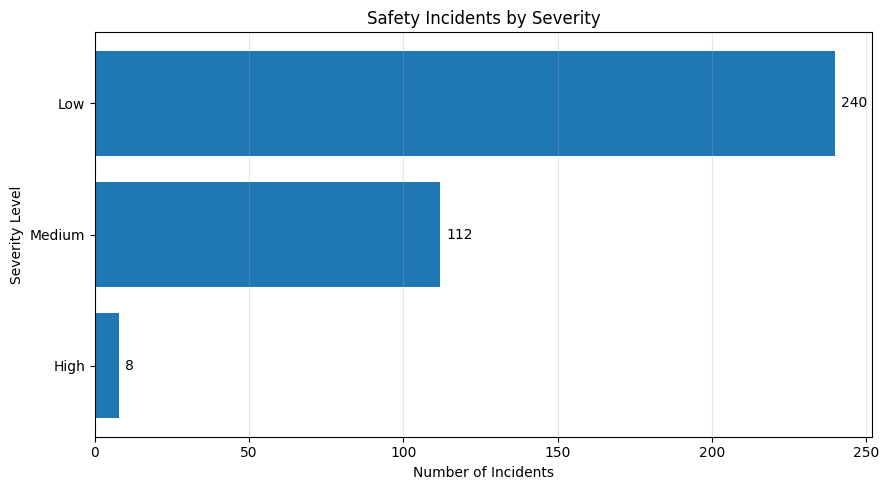

In [46]:
# Sort severity categories by incident count
severity_plot = severity_summary.sort_values(
    "incident_count",
    ascending=True
)

plt.figure(figsize=(9, 5))

bars = plt.barh(
    severity_plot["severity"],
    severity_plot["incident_count"]
)

plt.bar_label(bars, fmt="%.0f", padding=4)

plt.title("Safety Incidents by Severity")
plt.xlabel("Number of Incidents")
plt.ylabel("Severity Level")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Root cause analysis

| Kolom | Arti |
|---|---|
| `root_cause` | Penyebab yang dicatat pada laporan insiden |
| `incident_count` | Jumlah insiden untuk setiap penyebab |
| `percentage` | Persentase dari seluruh 360 catatan insiden |
| `total_days_lost` | Jumlah hari kerja hilang yang terkait dengan setiap penyebab |

In [47]:
# Analyze the recorded root causes of safety incidents

root_cause_summary = pd.read_sql_query("""
    SELECT
        COALESCE(NULLIF(TRIM(root_cause), ''), 'Unknown') AS root_cause,
        COUNT(*) AS incident_count,
        ROUND(
            COUNT(*) * 100.0 /
            (SELECT COUNT(*) FROM safety_incidents),
            2
        ) AS percentage,
        SUM(days_lost) AS total_days_lost
    FROM safety_incidents
    GROUP BY COALESCE(NULLIF(TRIM(root_cause), ''), 'Unknown')
    ORDER BY incident_count DESC
""", conn)

display(root_cause_summary)

,root_cause,incident_count,percentage,total_days_lost
0,Human Error,78,21.67,17
1,Procedural Gap,76,21.11,38
2,Training Gap,74,20.56,12
3,Environmental Factor,72,20.00,34
4,Equipment Failure,60,16.67,10


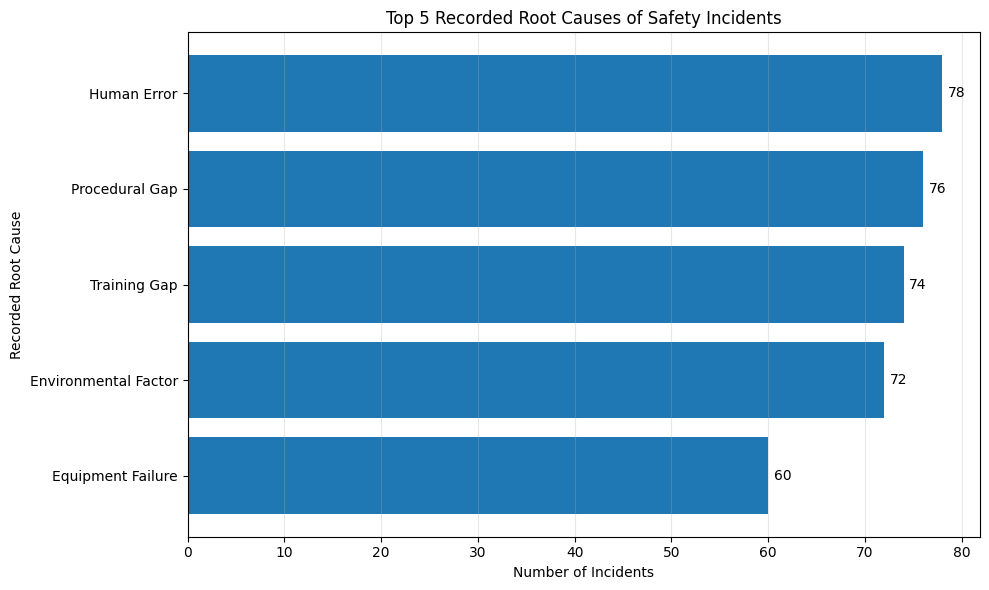

In [48]:
top_root_causes = (
    root_cause_summary
    .sort_values("incident_count", ascending=False)
    .head(5)
    .sort_values("incident_count", ascending=True)
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_root_causes["root_cause"],
    top_root_causes["incident_count"]
)

plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("Top 5 Recorded Root Causes of Safety Incidents")
plt.xlabel("Number of Incidents")
plt.ylabel("Recorded Root Cause")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

- Human Error adalah kategori dengan insiden terbanyak (78).
- Procedural Gap memiliki total hari kerja hilang terbesar (38 hari), meskipun jumlah insidennya sedikit di bawah Human Error. Environmental Factor juga patut diperhatikan dengan 34 hari kerja hilang.
- Kelima kategori relatif merata, dengan persentase antara 16,67% dan 21,67%.
- Prioritas keselamatan sebaiknya tidak ditentukan dari frekuensi insiden saja, tetapi juga dampaknya, seperti hari kerja yang hilang.

### Safety performance by mine site

**Objective:** Compare safety incident frequency and recorded impact across mine sites.

**Key questions:**
- Which mine site has the highest number of recorded incidents?
- Which site has the greatest total days lost?
- Do incident severity patterns differ across sites?

The analysis compares incident counts and days lost. Site-level incident counts are not treated as safety rates because workforce exposure may differ between sites (rates are calculated later in this section).

In [49]:
# Safety incident summary by mine site

site_safety = pd.read_sql_query("""
    SELECT
        site_id,
        site_name,
        COUNT(*) AS incident_count,
        ROUND(
            COUNT(*) * 100.0 /
            (SELECT COUNT(*) FROM safety_incidents),
            2
        ) AS percentage_of_incidents,
        SUM(days_lost) AS total_days_lost,
        ROUND(AVG(days_lost), 2) AS avg_days_lost,
        SUM(CASE WHEN severity = 'High' THEN 1 ELSE 0 END)
            AS high_severity_count
    FROM safety_incidents
    GROUP BY site_id, site_name
    ORDER BY incident_count DESC
""", conn)

display(site_safety)

,site_id,site_name,incident_count,percentage_of_incidents,total_days_lost,avg_days_lost,high_severity_count
0,COPP001,Copper Hills Mine,90,25.0,26,0.29,2
1,GOLD001,Golden Valley Mine,90,25.0,20,0.22,2
2,IRON001,Iron Ridge Mine,90,25.0,37,0.41,2
3,LITH001,Lithium Creek Mine,90,25.0,28,0.31,2


- Setiap lokasi mencatat 90 insiden (25%) dan 2 insiden High.
- Iron Ridge Mine memiliki total hari kerja hilang tertinggi (37 hari), diikuti Lithium Creek Mine (28), Copper Hills Mine (26), dan Golden Valley Mine terendah (20).

### Chart: recorded incidents by mine site

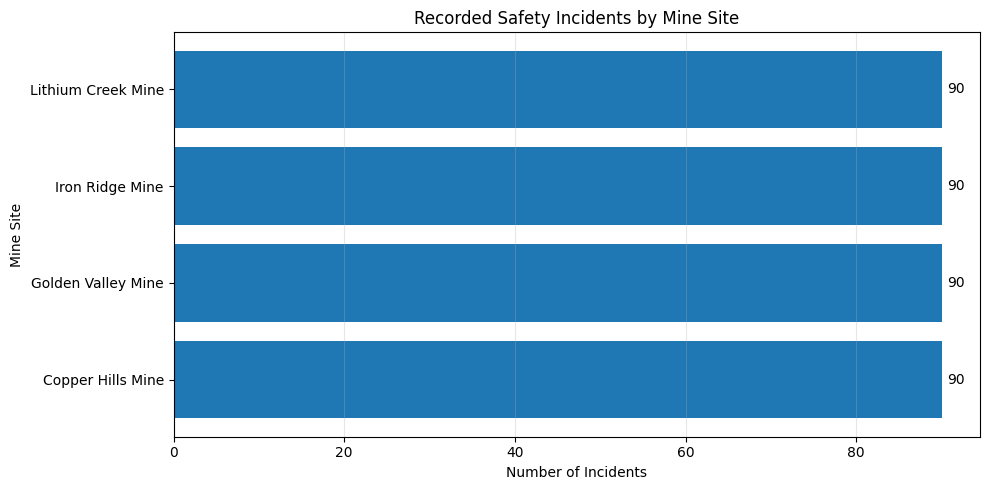

In [50]:
# Compare total recorded incidents by mine site
site_plot = site_safety.sort_values(
    "incident_count",
    ascending=True
)

plt.figure(figsize=(10, 5))

bars = plt.barh(
    site_plot["site_name"],
    site_plot["incident_count"]
)

plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("Recorded Safety Incidents by Mine Site")
plt.xlabel("Number of Incidents")
plt.ylabel("Mine Site")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Chart: total days lost by mine site

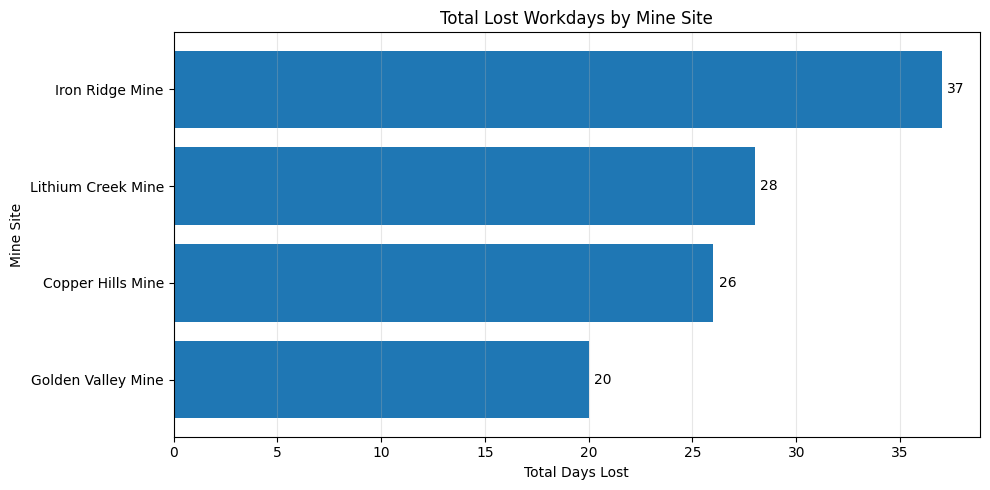

In [51]:
# Compare total days lost by mine site

site_days_lost = site_safety.sort_values(
    "total_days_lost",
    ascending=True
)

plt.figure(figsize=(10, 5))

bars = plt.barh(
    site_days_lost["site_name"],
    site_days_lost["total_days_lost"]
)

plt.bar_label(bars, fmt="%.0f", padding=4)

plt.title("Total Lost Workdays by Mine Site")
plt.xlabel("Total Days Lost")
plt.ylabel("Mine Site")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Safety Performance Interpretation**

Membandingkan frekuensi insiden dengan total hari kerja hilang memberikan gambaran hasil keselamatan yang lebih luas. Jumlah insiden mengukur frekuensi, sedangkan hari kerja hilang menunjukkan dampak yang tercatat. Lokasi dengan jumlah insiden sama dapat memiliki total hari hilang berbeda, sehingga kinerja keselamatan tidak dinilai dari frekuensi insiden saja.

**Keterbatasan:** Perbandingan ini memakai data sintetis dan hitungan mentah, serta belum memperhitungkan perbedaan jumlah tenaga kerja dan jam kerja.

### Safety metrics (TRIFR and LTIFR)

**Objective:** Evaluate the recorded safety indicators across mine sites using the `safety_metrics_summary` table.

- **LTI count:** Number of recorded Lost Time Injuries.
- **MTI count:** Number of recorded Medical Treatment Injuries.
- **TRIFR:** Total Recordable Injury Frequency Rate, as recorded in the dataset.
- **LTIFR:** Lost Time Injury Frequency Rate, as recorded in the dataset.
- **Total hours worked:** Recorded workforce exposure hours.

Analisis membandingkan metrik yang tercatat antar lokasi dan memeriksa konsistensinya dengan data insiden.

In [52]:
# Load the recorded safety metrics
safety_metrics = pd.read_sql_query("""
    SELECT
        site_id,
        site_name,
        total_hours_worked,
        lti_count,
        mti_count,
        trifr,
        ltifr
    FROM safety_metrics_summary
    ORDER BY site_name
""", conn)

display(safety_metrics)

,site_id,site_name,total_hours_worked,lti_count,mti_count,trifr,ltifr
0,COPP001,Copper Hills Mine,1226400,2,8,8.15,1.63
1,GOLD001,Golden Valley Mine,5256000,2,8,1.90,0.38
2,IRON001,Iron Ridge Mine,3723000,2,8,2.69,0.54
3,LITH001,Lithium Creek Mine,1971000,2,8,5.07,1.01


### Consistency check: injury counts vs incident records

In [53]:
# Compare injury counts in the summary with recorded incident data

incident_injury_check = pd.read_sql_query("""
    SELECT
        site_id,
        site_name,
        SUM(CASE
            WHEN LOWER(incident_type) LIKE '%lti%'
              OR LOWER(incident_type) LIKE '%lost time%'
            THEN 1 ELSE 0
        END) AS recorded_lti_matches,
        SUM(CASE
            WHEN LOWER(incident_type) LIKE '%mti%'
              OR LOWER(incident_type) LIKE '%medical treatment%'
            THEN 1 ELSE 0
        END) AS recorded_mti_matches,
        COUNT(*) AS total_incidents
    FROM safety_incidents
    GROUP BY site_id, site_name
    ORDER BY site_name
""", conn)

safety_comparison = safety_metrics.merge(
    incident_injury_check,
    on=["site_id", "site_name"],
    how="left"
)

display(safety_comparison)

,site_id,site_name,total_hours_worked,lti_count,mti_count,trifr,ltifr,recorded_lti_matches,recorded_mti_matches,total_incidents
0,COPP001,Copper Hills Mine,1226400,2,8,8.15,1.63,2,8,90
1,GOLD001,Golden Valley Mine,5256000,2,8,1.90,0.38,2,8,90
2,IRON001,Iron Ridge Mine,3723000,2,8,2.69,0.54,2,8,90
3,LITH001,Lithium Creek Mine,1971000,2,8,5.07,1.01,2,8,90


| Indikator | Hasil |
|---|---|
| Jumlah lokasi di tabel ringkasan | 4 |
| Insiden per lokasi | 90 |
| Total insiden di empat lokasi | 360 |
| LTI per lokasi | 2 |
| MTI per lokasi | 8 |
| Kesesuaian hitungan LTI/MTI | Cocok dengan kategori yang terdeteksi |

Jumlah insiden tiap lokasi sama (90), tetapi TRIFR dan LTIFR berbeda karena total jam kerja berbeda. Copper Hills Mine memiliki TRIFR tertinggi (8,15) dan Golden Valley Mine terendah (1,90). Nilai ini perlu ditafsirkan bersama jam kerja dan definisi perhitungan metrik, bukan langsung sebagai bukti bahwa satu lokasi lebih aman secara keseluruhan.

### Chart: TRIFR and LTIFR by mine site

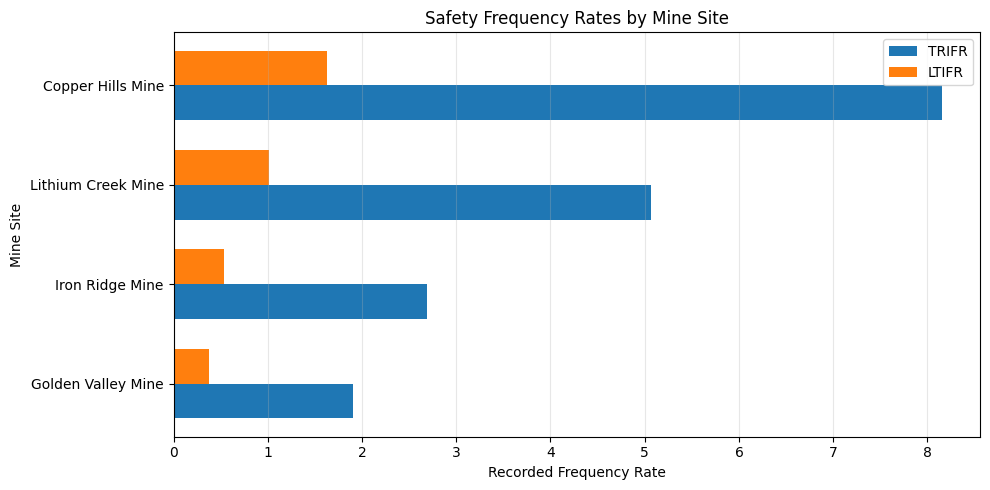

In [54]:
safety_plot = safety_metrics.sort_values("trifr", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5))

y = np.arange(len(safety_plot))
height = 0.35

ax.barh(
    y - height / 2,
    safety_plot["trifr"],
    height,
    label="TRIFR"
)

ax.barh(
    y + height / 2,
    safety_plot["ltifr"],
    height,
    label="LTIFR"
)

ax.set_yticks(y)
ax.set_yticklabels(safety_plot["site_name"])
ax.set_xlabel("Recorded Frequency Rate")
ax.set_ylabel("Mine Site")
ax.set_title("Safety Frequency Rates by Mine Site")
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretasi grafik keselamatan**

- Copper Hills Mine: TRIFR tertinggi (8,15) dan LTIFR 1,63.
- Lithium Creek Mine: TRIFR 5,07 dan LTIFR 1,01.
- Iron Ridge Mine: TRIFR 2,69 dan LTIFR 0,54.
- Golden Valley Mine: TRIFR terendah (1,90) dan LTIFR 0,38.

Berdasarkan indikator tercatat pada dataset sintetis ini, Copper Hills Mine perlu diprioritaskan untuk pemeriksaan lebih lanjut. Angka ini belum membuktikan penyebab insiden atau kondisi keselamatan aktual tambang.

### Incident mix, timing, and open investigations
*(Analisis tambahan.)* TRIFR hanya menghitung LTI dan MTI (10 dari 90 insiden per lokasi). Bagian ini melengkapinya dengan: (1) laju seluruh insiden per juta jam kerja, (2) komposisi jenis insiden, (3) tren bulanan insiden dan hari hilang, dan (4) status investigasi.

,site_name,total_hours_worked,trifr,incident_count,total_days_lost,incidents_per_million_hours,lost_days_per_million_hours
0,Copper Hills Mine,1226400,8.15,90,26,73.4,21.2
3,Lithium Creek Mine,1971000,5.07,90,28,45.7,14.2
2,Iron Ridge Mine,3723000,2.69,90,37,24.2,9.9
1,Golden Valley Mine,5256000,1.90,90,20,17.1,3.8


,incident_type,incident_count,percentage,total_days_lost
0,Near Miss,160,44.4,0
1,First Aid Injury (FAI),80,22.2,0
2,Potential Significant Incident (PSI),60,16.7,0
3,Medical Treatment Injury (MTI),32,8.9,0
4,Environmental Incident,20,5.6,0
5,Lost Time Injury (LTI),8,2.2,111


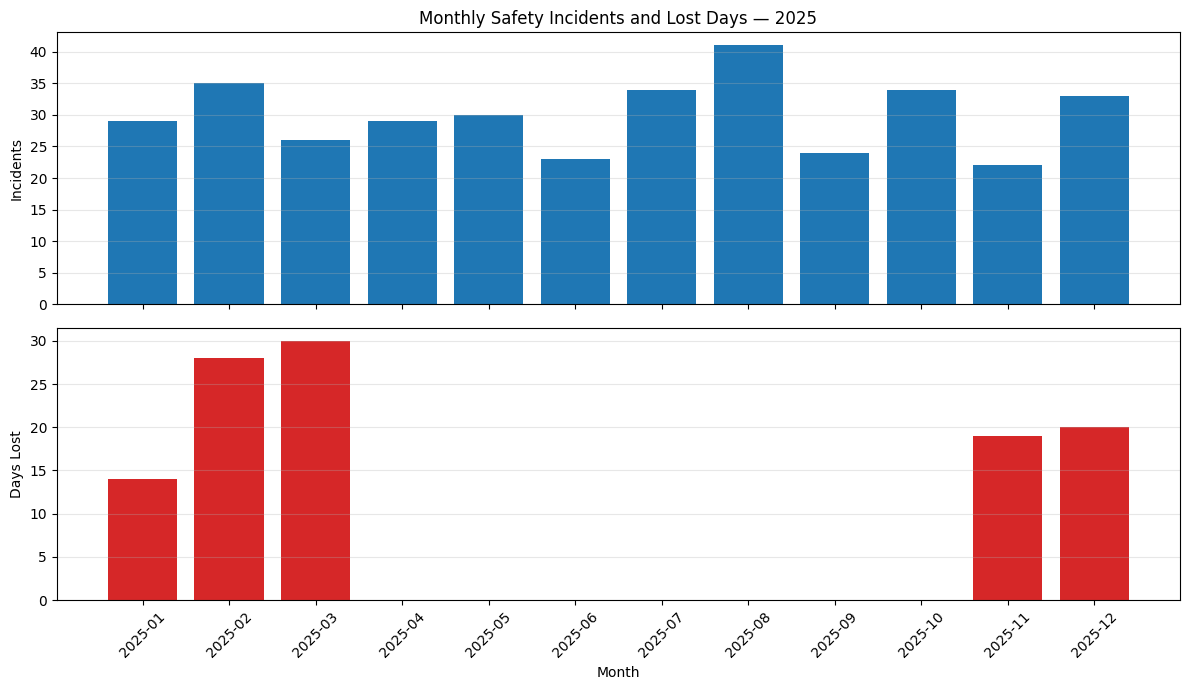

,severity,closed,under_investigation,total
0,Low,175,65,240
1,Medium,82,30,112
2,High,6,2,8


In [55]:
# 1) All recorded incidents per million hours worked
incident_rate = safety_metrics[["site_name", "total_hours_worked", "trifr"]].merge(
    site_safety[["site_name", "incident_count", "total_days_lost"]],
    on="site_name"
)
incident_rate["incidents_per_million_hours"] = (
    incident_rate["incident_count"] / incident_rate["total_hours_worked"] * 1_000_000
).round(1)
incident_rate["lost_days_per_million_hours"] = (
    incident_rate["total_days_lost"] / incident_rate["total_hours_worked"] * 1_000_000
).round(1)

display(incident_rate.sort_values("incidents_per_million_hours", ascending=False))

# 2) Incident type mix
incident_type_summary = pd.read_sql_query("""
    SELECT
        incident_type,
        COUNT(*) AS incident_count,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM safety_incidents), 1) AS percentage,
        SUM(days_lost) AS total_days_lost
    FROM safety_incidents
    GROUP BY incident_type
    ORDER BY incident_count DESC
""", conn)

display(incident_type_summary)

# 3) Monthly incidents and lost days
monthly_safety = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', date) AS month,
        COUNT(*) AS incident_count,
        SUM(days_lost) AS total_days_lost
    FROM safety_incidents
    GROUP BY strftime('%Y-%m', date)
    ORDER BY month
""", conn)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].bar(monthly_safety["month"], monthly_safety["incident_count"])
axes[0].set_ylabel("Incidents")
axes[0].set_title("Monthly Safety Incidents and Lost Days — 2025")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(monthly_safety["month"], monthly_safety["total_days_lost"], color="tab:red")
axes[1].set_ylabel("Days Lost")
axes[1].set_xlabel("Month")
axes[1].grid(axis="y", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4) Investigation status by severity
investigation_status_summary = pd.read_sql_query("""
    SELECT
        severity,
        SUM(CASE WHEN investigation_status = 'Closed' THEN 1 ELSE 0 END) AS closed,
        SUM(CASE WHEN investigation_status = 'Under Investigation' THEN 1 ELSE 0 END)
            AS under_investigation,
        COUNT(*) AS total
    FROM safety_incidents
    GROUP BY severity
    ORDER BY total DESC
""", conn)

display(investigation_status_summary)

**Interpretasi tambahan keselamatan**

- Setelah dinormalkan terhadap jam kerja, laju seluruh insiden mengikuti urutan yang sama dengan TRIFR: Copper Hills Mine sekitar 73,4 insiden per juta jam, Lithium Creek 45,7, Iron Ridge 24,2, dan Golden Valley 17,1. Jumlah insiden yang sama (90) menyembunyikan perbedaan paparan yang besar.
- Near Miss adalah jenis insiden terbanyak (160, sekitar 44%), diikuti First Aid Injury (80) dan Potential Significant Incident (60). Ada 8 LTI yang menyumbang seluruh 111 hari hilang. Pelaporan Near Miss yang tinggi dapat menjadi indikator awal yang berguna.
- Hari hilang terkonsentrasi pada Januari–Maret dan November–Desember. Tidak ada hari hilang pada April–Oktober, sedangkan jumlah insiden tertinggi terjadi pada Agustus (41).
- 97 insiden masih berstatus *Under Investigation*, termasuk 2 insiden High. Insiden High yang belum ditutup layak diprioritaskan.
- Keterbatasan: setiap lokasi memiliki jumlah insiden, LTI, MTI, dan insiden High yang identik, yang mengindikasikan data sintetis dengan pola seragam.

## 9. Extended Analysis

Bagian ini memakai kolom yang belum dianalisis sebelumnya: `shift_1_tonnes`/`shift_2_tonnes`, `metal_produced`, `head_grade`, `recovery_rate`, `fuel_consumed_liters`, dan pola harian `tonnes_mined`. *(Analisis tambahan.)*

### 9.1 Shift 1 vs Shift 2
Apakah salah satu shift secara konsisten menambang lebih banyak? Hanya lokasi berstatus *Operational* yang dibandingkan.

,site_name,shift_1_tonnes,shift_2_tonnes,total_tonnes_mined,shift_1_share_pct,shifts_add_up_to_total
0,Iron Ridge Mine,23486483,23449005,46935488,50.04,True
1,Golden Valley Mine,6018211,6081074,12099285,49.74,True
2,Lithium Creek Mine,325359,328183,653542,49.78,True
3,Copper Hills Mine,9065,9431,18496,49.01,True


,site_name,mean,std,min,max
0,Copper Hills Mine,49.0,3.0,43.4,54.5
1,Golden Valley Mine,49.7,3.0,45.0,55.0
2,Iron Ridge Mine,50.0,2.9,45.1,55.0
3,Lithium Creek Mine,49.8,2.8,45.0,55.0


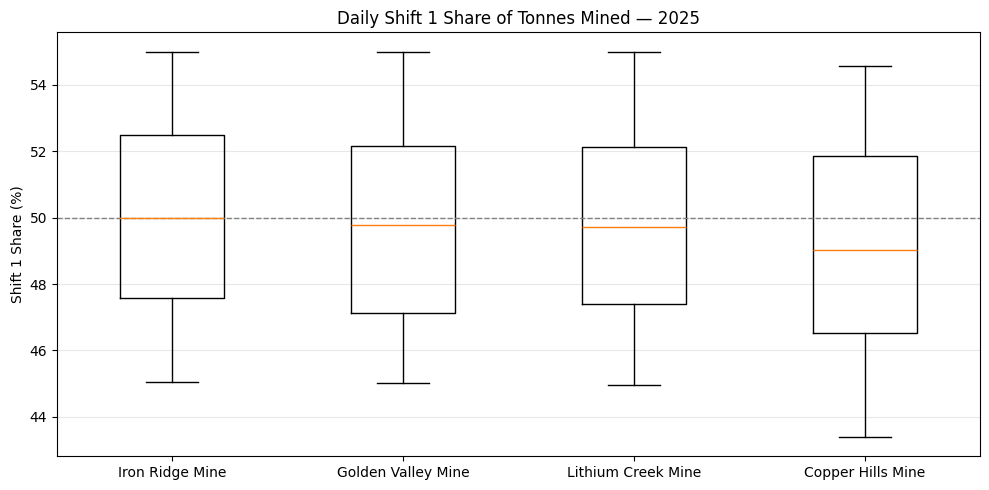

In [56]:
shift_summary = pd.read_sql_query("""
    SELECT
        site_name,
        SUM(shift_1_tonnes) AS shift_1_tonnes,
        SUM(shift_2_tonnes) AS shift_2_tonnes,
        SUM(tonnes_mined) AS total_tonnes_mined
    FROM daily_production
    WHERE status = 'Operational'
    GROUP BY site_name
    ORDER BY total_tonnes_mined DESC
""", conn)

shift_summary["shift_1_share_pct"] = (
    shift_summary["shift_1_tonnes"] / shift_summary["total_tonnes_mined"] * 100
).round(2)
shift_summary["shifts_add_up_to_total"] = (
    shift_summary["shift_1_tonnes"] + shift_summary["shift_2_tonnes"]
    == shift_summary["total_tonnes_mined"]
)

display(shift_summary)

# Day-to-day spread of the Shift 1 share
shift_daily = pd.read_sql_query("""
    SELECT site_name, shift_1_tonnes * 100.0 / tonnes_mined AS shift_1_share_pct
    FROM daily_production
    WHERE status = 'Operational' AND tonnes_mined > 0
""", conn)

display(
    shift_daily.groupby("site_name")["shift_1_share_pct"]
    .agg(mean="mean", std="std", min="min", max="max")
    .round(1)
    .reset_index()
)

site_order = shift_summary["site_name"].tolist()
plt.figure(figsize=(10, 5))
plt.boxplot(
    [shift_daily.loc[shift_daily["site_name"] == s, "shift_1_share_pct"] for s in site_order]
)
plt.xticks(range(1, len(site_order) + 1), site_order)
plt.axhline(50, linestyle="--", linewidth=1, color="gray")
plt.title("Daily Shift 1 Share of Tonnes Mined — 2025")
plt.ylabel("Shift 1 Share (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi shift**

- Shift 1 dan Shift 2 menambang hampir sama besar: porsi Shift 1 sekitar 49,0%–50,0% per lokasi, dan jumlah kedua shift selalu sama dengan `tonnes_mined`.
- Porsi harian bergerak sekitar 43%–55% di sekitar 50%, dengan simpangan baku sekitar 3 poin. Tidak ada shift yang unggul secara konsisten.
- Dari sisi produksi, pergantian shift bukan sumber perbedaan kinerja pada dataset ini.

### 9.2 Cost per unit of metal produced
Biaya per ton material ditambang tidak setara antar komoditas. Di sini biaya juga dihitung per unit `metal_produced` dan dibandingkan dengan `cost_per_unit_target` dari `mine_sites`. Satuan logam tidak didokumentasikan di dataset (mis. emas kemungkinan dalam ons), sehingga angka antar lokasi **tidak** dibandingkan satu sama lain.

In [57]:
unit_cost = pd.read_sql_query("""
    SELECT
        p.site_name,
        p.commodity,
        SUM(p.tonnes_mined) AS tonnes_mined,
        SUM(p.metal_produced) AS metal_produced,
        SUM(c.total_cost_aud) AS total_cost_aud,
        m.cost_per_unit_target
    FROM daily_production AS p
    INNER JOIN daily_costs AS c
        ON p.date = c.date AND p.site_id = c.site_id
    INNER JOIN mine_sites AS m
        ON p.site_id = m.site_id
    WHERE p.status = 'Operational'
    GROUP BY p.site_id, p.site_name, p.commodity, m.cost_per_unit_target
    ORDER BY tonnes_mined DESC
""", conn)

unit_cost["cost_per_tonne_mined_aud"] = unit_cost["total_cost_aud"] / unit_cost["tonnes_mined"]
unit_cost["cost_per_unit_metal_aud"] = unit_cost["total_cost_aud"] / unit_cost["metal_produced"]
unit_cost["per_tonne_mined_vs_target_pct"] = (
    (unit_cost["cost_per_tonne_mined_aud"] / unit_cost["cost_per_unit_target"] - 1) * 100
)
unit_cost["per_unit_metal_vs_target_pct"] = (
    (unit_cost["cost_per_unit_metal_aud"] / unit_cost["cost_per_unit_target"] - 1) * 100
)

display(
    unit_cost[
        [
            "site_name", "commodity", "metal_produced", "cost_per_unit_target",
            "cost_per_tonne_mined_aud", "per_tonne_mined_vs_target_pct",
            "cost_per_unit_metal_aud", "per_unit_metal_vs_target_pct"
        ]
    ].round(2)
)

,site_name,commodity,metal_produced,cost_per_unit_target,cost_per_tonne_mined_aud,per_tonne_mined_vs_target_pct,cost_per_unit_metal_aud,per_unit_metal_vs_target_pct
0,Iron Ridge Mine,Iron Ore,44593891.89,27.00,27.05,0.19,28.47,5.45
1,Golden Valley Mine,Gold,412994.36,2500.00,80.25,-96.79,2351.02,-5.96
2,Lithium Creek Mine,Lithium,5775.89,640.00,638.71,-0.20,72269.95,11192.18
3,Copper Hills Mine,Copper,435.87,1.85,4078.31,220349.12,173061.69,9354585.70


**Interpretasi biaya per unit logam**

- **Iron Ridge** dan **Lithium Creek**: biaya per ton ditambang (A$27,05 dan A$638,71) hampir sama dengan `cost_per_unit_target` (27 dan 640), selisih sekitar 0,2%.
- **Golden Valley**: target 2.500 cocok dengan biaya per unit logam (sekitar A$2.351, sekitar 6% di bawah target), bukan dengan biaya per ton ditambang (sekitar A$80).
- **Copper Hills**: target 1,85 tidak cocok dengan ukuran mana pun (A$4.078 per ton ditambang; sekitar A$173.062 per unit logam). Pada audit database, `cost_per_unit` Copper terbukti dihitung per pon (biaya ÷ `metal_produced` × sekitar 2.200), dengan rata-rata sekitar A$78,8 per pon, atau jauh di atas target 1,85. Satuan atau nilai target ini perlu dikonfirmasi sebelum dipakai untuk menilai kinerja biaya.
- Artinya `cost_per_unit_target` tidak berbasis satuan yang sama di semua lokasi. Hasil ini adalah pengamatan atas pola angka, bukan kesimpulan tentang kinerja biaya.

### 9.3 Head grade and recovery rate
Memeriksa apakah `head_grade` dan `recovery_rate` berubah sepanjang tahun, dan seberapa jauh keduanya dari target di `mine_sites`.

,site_name,avg_head_grade,target_head_grade,head_grade_cv_pct,avg_recovery_pct,target_recovery_pct,min_recovery_pct,max_recovery_pct,days_recovery_at_100,grade_recovery_corr
0,Copper Hills Mine,2.80,2.8,2.88,86.99,88.0,84.5,89.7,0,-0.05
1,Golden Valley Mine,1.20,1.2,3.02,90.13,91.0,87.4,92.8,0,0.06
2,Iron Ridge Mine,61.94,62.0,2.99,96.96,98.0,94.1,100.0,12,-0.02
3,Lithium Creek Mine,1.30,1.3,2.92,69.31,70.0,67.2,71.4,0,-0.07


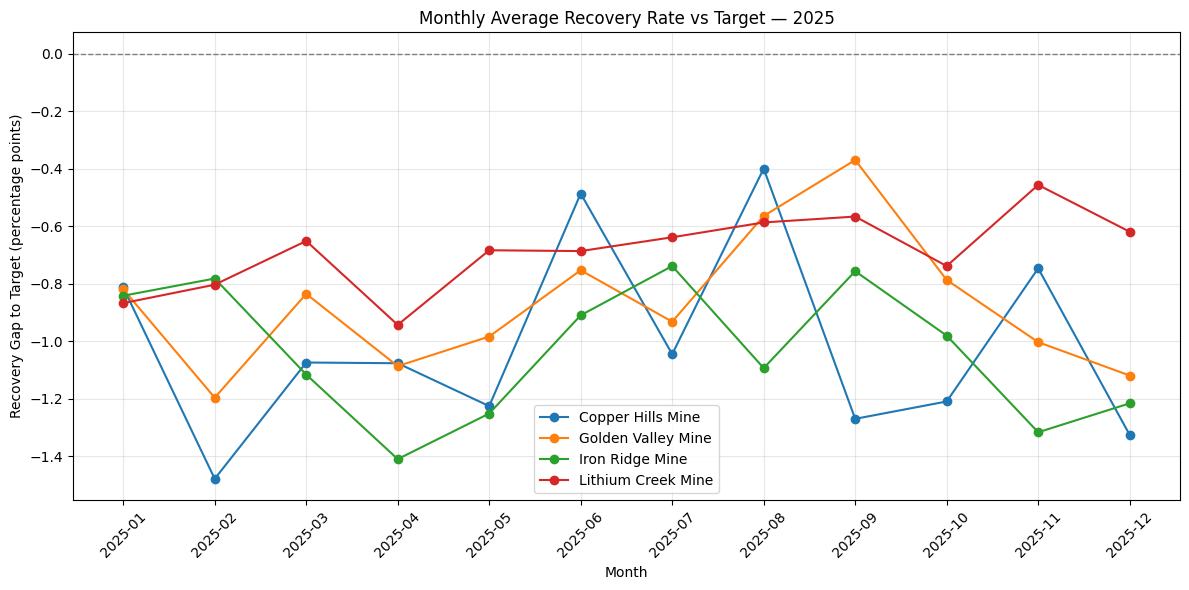

In [58]:
gr_daily = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', p.date) AS month,
        p.site_name,
        p.head_grade,
        p.recovery_rate,
        m.target_head_grade,
        m.target_recovery_rate
    FROM daily_production AS p
    INNER JOIN mine_sites AS m
        ON p.site_id = m.site_id
    WHERE p.status = 'Operational'
""", conn)

grade_summary = gr_daily.groupby("site_name").agg(
    avg_head_grade=("head_grade", "mean"),
    target_head_grade=("target_head_grade", "first"),
    head_grade_cv_pct=("head_grade", lambda s: s.std() / s.mean() * 100),
    avg_recovery_pct=("recovery_rate", "mean"),
    target_recovery_pct=("target_recovery_rate", "first"),
    min_recovery_pct=("recovery_rate", "min"),
    max_recovery_pct=("recovery_rate", "max"),
    days_recovery_at_100=("recovery_rate", lambda s: int((s >= 99.9).sum()))
)
grade_summary["grade_recovery_corr"] = (
    gr_daily.groupby("site_name")[["head_grade", "recovery_rate"]]
    .apply(lambda g: g["head_grade"].corr(g["recovery_rate"]))
)

display(grade_summary.round(2).reset_index())

# Monthly recovery gap to target
monthly_recovery = (
    gr_daily.groupby(["month", "site_name"])
    .agg(avg_recovery=("recovery_rate", "mean"), target=("target_recovery_rate", "first"))
    .reset_index()
)
monthly_recovery["recovery_gap_pts"] = monthly_recovery["avg_recovery"] - monthly_recovery["target"]
recovery_pivot = monthly_recovery.pivot(index="month", columns="site_name", values="recovery_gap_pts")

plt.figure(figsize=(12, 6))
for site in recovery_pivot.columns:
    plt.plot(recovery_pivot.index, recovery_pivot[site], marker="o", label=site)
plt.axhline(0, linestyle="--", linewidth=1, color="gray")
plt.title("Monthly Average Recovery Rate vs Target — 2025")
plt.xlabel("Month")
plt.ylabel("Recovery Gap to Target (percentage points)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi grade dan recovery**

- Rata-rata `head_grade` berada tepat di sekitar target di semua lokasi (Iron Ridge 61,9 vs 62; Golden Valley 1,20; Lithium Creek 1,30; Copper Hills 2,80). Variasi hariannya kecil, sekitar 3% (koefisien variasi).
- Rata-rata `recovery_rate` berada di bawah target pada **setiap bulan** di semua lokasi (selisih bulanan sekitar 0,4–1,5 poin; rata-rata tahunan 0,7–1,0 poin). Selisihnya konsisten dan tidak musiman, sehingga lebih mirip offset sistematis daripada fluktuasi acak.
- Korelasi harian antara head grade dan recovery mendekati nol (|r| ≤ 0,07), jadi recovery tidak bergantung pada kadar bijih pada data ini.
- Iron Ridge mencatat recovery 100,0% pada 12 hari. Nilai di batas atas ini perlu diperiksa apakah merupakan pemotongan (*capping*) saat pencatatan.

### 9.4 Fuel consumption by equipment
`fuel_consumed_liters` di tabel peralatan dibandingkan menurut jenis dan mode operasi, lalu dicocokkan dengan `fuel_cost_aud` di tabel biaya.

,equipment_type,operation_mode,units,total_fuel_liters,liters_per_operating_hour,avg_liters_per_record,share_of_tracked_fuel_pct
0,Excavator,Conventional,5,14082308,400.0,7716.0,47.3
1,Haul Truck,Conventional,5,6289146,180.0,3446.0,21.1
2,Haul Truck,Autonomous,3,4334363,180.0,3958.0,14.6
3,Dozer,Conventional,4,3103591,120.0,2126.0,10.4
4,LHD Loader,Conventional,3,1442292,80.0,1317.0,4.8
5,Jumbo Drill,Conventional,2,520792,60.0,713.0,1.7


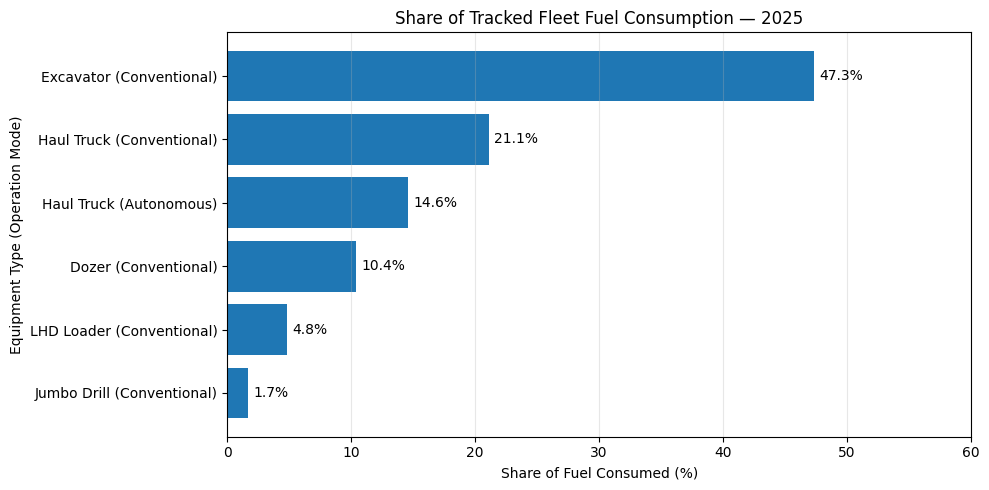

,tracked_fleet_liters,site_fuel_cost_aud,implied_aud_per_liter
0,29772492,4.920189e+08,16.53


In [59]:
fuel_summary = pd.read_sql_query("""
    SELECT
        equipment_type,
        CASE WHEN autonomous = 1 THEN 'Autonomous' ELSE 'Conventional' END AS operation_mode,
        COUNT(DISTINCT equipment_id) AS units,
        SUM(fuel_consumed_liters) AS total_fuel_liters,
        ROUND(SUM(fuel_consumed_liters) * 1.0 / SUM(operating_hours), 1) AS liters_per_operating_hour,
        ROUND(AVG(fuel_consumed_liters), 0) AS avg_liters_per_record
    FROM equipment_performance
    GROUP BY equipment_type, operation_mode
    ORDER BY total_fuel_liters DESC
""", conn)

fuel_summary["share_of_tracked_fuel_pct"] = (
    fuel_summary["total_fuel_liters"] / fuel_summary["total_fuel_liters"].sum() * 100
).round(1)

display(fuel_summary)

fuel_plot = fuel_summary.sort_values("share_of_tracked_fuel_pct", ascending=True)
labels = fuel_plot["equipment_type"] + " (" + fuel_plot["operation_mode"] + ")"

plt.figure(figsize=(10, 5))
bars = plt.barh(labels, fuel_plot["share_of_tracked_fuel_pct"])
plt.bar_label(bars, fmt="%.1f%%", padding=4)
plt.title("Share of Tracked Fleet Fuel Consumption — 2025")
plt.xlabel("Share of Fuel Consumed (%)")
plt.ylabel("Equipment Type (Operation Mode)")
plt.xlim(0, 60)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Reconcile fleet fuel volume with site-level fuel cost
fuel_reconciliation = pd.read_sql_query("""
    SELECT
        (SELECT SUM(fuel_consumed_liters) FROM equipment_performance) AS tracked_fleet_liters,
        (SELECT SUM(fuel_cost_aud) FROM daily_costs) AS site_fuel_cost_aud
""", conn)
fuel_reconciliation["implied_aud_per_liter"] = (
    fuel_reconciliation["site_fuel_cost_aud"] / fuel_reconciliation["tracked_fleet_liters"]
).round(2)

display(fuel_reconciliation)

**Interpretasi bahan bakar**

- Excavator (5 unit) menyumbang sekitar 47% bahan bakar armada yang tercatat, diikuti Haul Truck sekitar 36% (konvensional dan otonom digabung). Konsumsi per jam operasi sangat berbeda antar jenis: Excavator 400 L/jam, Haul Truck 180 L/jam, Dozer 120, LHD Loader 80, Jumbo Drill 60.
- Konsumsi per jam operasi bernilai tetap untuk setiap jenis alat, jadi bahan bakar pada dataset ini hanya mengikuti jam operasi. Truk otonom memakai 180 L/jam, sama dengan truk konvensional. Konsumsi per catatan mereka lebih tinggi (sekitar 3.958 vs 3.446 L) hanya karena jam operasinya lebih panjang.
- Total bahan bakar armada tercatat sekitar 29,8 juta liter, sedangkan `fuel_cost_aud` mencapai sekitar A$492 juta. Itu setara sekitar A$16,5 per liter, jauh di atas kisaran harga bahan bakar yang wajar (asumsi eksternal, sekitar A$1–2 per liter). Volume di tabel peralatan karenanya tidak bisa dipakai untuk merekonsiliasi biaya bahan bakar. Kemungkinan tabel hanya mencakup sebagian armada, atau sumber biayanya berbeda.

### 9.5 Anomaly detection on daily production
Hari dengan produksi yang menyimpang ditandai memakai *robust z-score* (median dan MAD) per lokasi. Ambang |z| > 3,5 dipilih karena tidak terpengaruh oleh outlier itu sendiri.

,site_name,days,anomaly_days,anomalies_on_downtime_days,downtime_days,high_side_anomalies
0,Copper Hills Mine,365,8,8,8,0
1,Golden Valley Mine,365,8,8,8,0
2,Iron Ridge Mine,365,8,8,8,0
3,Lithium Creek Mine,365,9,9,10,0


,date,sites_affected,avg_downtime_hours
0,2025-01-22,1,12.0
1,2025-03-11,1,7.2
2,2025-03-15,4,16.8
3,2025-03-16,4,16.8
4,2025-06-15,4,16.8
5,2025-06-16,4,16.8
6,2025-09-15,4,16.8
7,2025-09-16,4,16.8
8,2025-12-15,4,16.8
9,2025-12-16,4,16.8


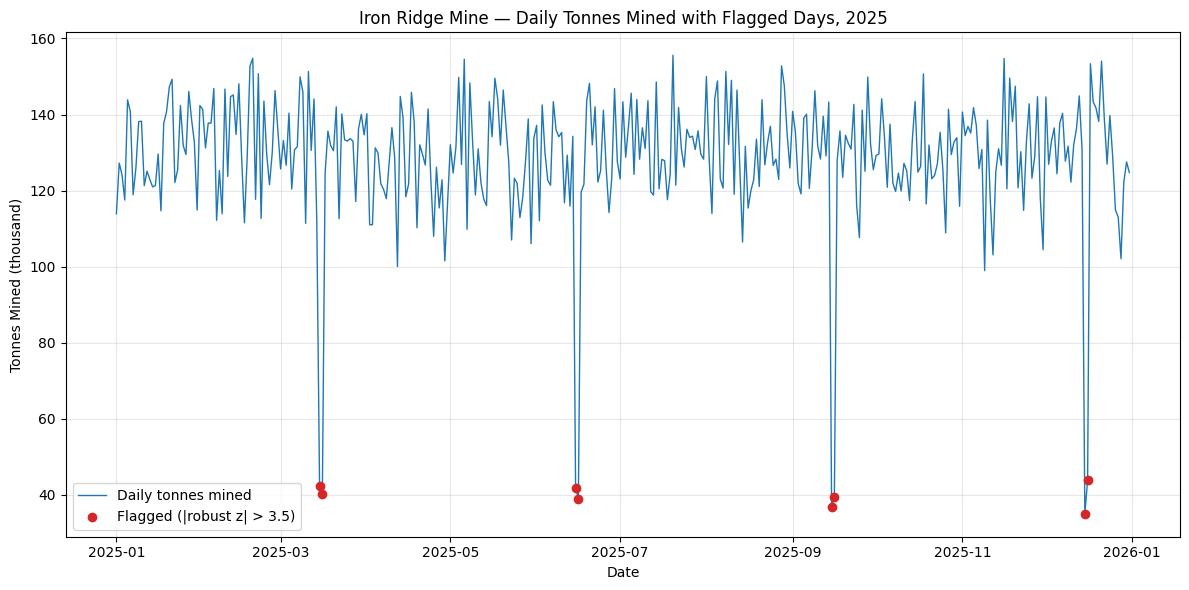

In [60]:
anomaly_df = pd.read_sql_query("""
    SELECT
        site_name, date, tonnes_mined, plan_adherence_pct,
        downtime_hours, weather_delay_hours
    FROM daily_production
    WHERE status = 'Operational'
""", conn)

def robust_z(s):
    median = s.median()
    mad = (s - median).abs().median()
    return 0.6745 * (s - median) / mad

anomaly_df["robust_z"] = anomaly_df.groupby("site_name")["tonnes_mined"].transform(robust_z)
anomaly_df["is_anomaly"] = anomaly_df["robust_z"].abs() > 3.5
anomaly_df["has_downtime"] = anomaly_df["downtime_hours"] > 0
anomaly_df["anomaly_with_downtime"] = anomaly_df["is_anomaly"] & anomaly_df["has_downtime"]

anomaly_summary = anomaly_df.groupby("site_name").agg(
    days=("date", "count"),
    anomaly_days=("is_anomaly", "sum"),
    anomalies_on_downtime_days=("anomaly_with_downtime", "sum"),
    downtime_days=("has_downtime", "sum"),
    high_side_anomalies=("robust_z", lambda s: int((s > 3.5).sum()))
).reset_index()

display(anomaly_summary)

# Which dates have downtime, and how many sites are affected?
downtime_calendar = (
    anomaly_df[anomaly_df["has_downtime"]]
    .groupby("date")
    .agg(sites_affected=("site_name", "count"), avg_downtime_hours=("downtime_hours", "mean"))
    .round(1)
    .reset_index()
)
display(downtime_calendar)

# Chart: Iron Ridge daily production with flagged days
iron = anomaly_df[anomaly_df["site_name"] == "Iron Ridge Mine"].copy()
iron["date"] = pd.to_datetime(iron["date"])
flagged = iron[iron["is_anomaly"]]

plt.figure(figsize=(12, 6))
plt.plot(iron["date"], iron["tonnes_mined"] / 1_000, linewidth=1, label="Daily tonnes mined")
plt.scatter(flagged["date"], flagged["tonnes_mined"] / 1_000, color="tab:red", zorder=3,
            label="Flagged (|robust z| > 3.5)")
plt.title("Iron Ridge Mine — Daily Tonnes Mined with Flagged Days, 2025")
plt.xlabel("Date")
plt.ylabel("Tonnes Mined (thousand)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretasi anomali**

- Hari yang ditandai: 8 hari di Iron Ridge, Golden Valley, dan Copper Hills, serta 9 hari di Lithium Creek. **Semuanya jatuh pada hari downtime**, dan tidak ada hari normal yang ditandai. Tidak ada anomali ke sisi atas (produksi tidak pernah melonjak secara ekstrem).
- Downtime terjadi pada tanggal yang sama di keempat lokasi: **15–16 Maret, Juni, September, dan Desember**. Pola dua hari per kuartal ini lebih mirip penghentian terjadwal daripada kerusakan acak. Ini inferensi dari polanya, karena dataset tidak membedakan downtime terencana dan tidak terencana.
- Lithium Creek memiliki dua hari tambahan, 22 Januari dan 11 Maret, bersamaan dengan `weather_delay_hours` pada dua hari itu.
- Rekomendasi: tambahkan kolom jenis downtime (terencana/tidak terencana) agar dampak penghentian kuartalan dapat dipisahkan dari gangguan operasional.

## 10. Key Findings and Recommendations

### 1. Production
Iron Ridge Mine and Golden Valley Mine produced about 99% of total tonnes mined (46.9 Mt and 12.1 Mt). Every producing site reached roughly 92.5%–93.9% of its annual target, and average recovery was 0.7–1.0 points below target. Downtime days (8–10 per site) account for an estimated 1.5%–1.8% of annual output.

### 2. Cost
Total operating cost was about AUD 2.74 billion. Labor, equipment, and fuel make up about 86% of costs. Cost per tonne ranges from AUD 27.05 (Iron Ridge) to AUD 4,078.31 (Copper Hills). Monthly cost per tonne is stable at about AUD 45–46, so cost moves almost proportionally with tonnage (r = 0.982).

### 3. Equipment Effectiveness
Haul Trucks recorded the highest average OEE at 84.23%, while Jumbo Drills recorded the lowest at 49.55%. OEE equals availability × utilization in this dataset, so differences come from utilization rather than availability. The three autonomous haul trucks at Iron Ridge reach about 91.6% OEE versus roughly 79%–81% for conventional trucks.

### 4. Maintenance and Breakdown
LHD Loaders recorded the highest average breakdown hours per equipment unit at 67.10 hours. Haul Trucks recorded the lowest at 46.25 hours per unit. Breakdowns are rare (about 1.9% of records) but cut OEE from 76.67% to 51.10% when they occur.

### 5. Maintenance Cost
Excavators had the highest average maintenance cost per unit, at approximately AUD 1.02 million. Haul Trucks had the lowest, at approximately AUD 920,278 per unit. The equipment table covers only about 10% of site-level maintenance cost.

### 6. Safety
The dataset recorded 360 safety incidents. High-severity incidents accounted for 8 records and all 111 lost days. Human Error was the most frequently recorded root cause (78 incidents) and Procedural Gap the largest in lost days (38). Copper Hills Mine has the highest TRIFR (8.15) and the highest incident rate per million hours; 97 incidents, including 2 High, are still under investigation.

### 7. Extended Analysis
Shift 1 and Shift 2 each mine about 50% of tonnes, so shifts do not explain performance differences. Head grade is on target, while recovery is below target in every month at every site, a consistent offset of roughly 0.4–1.5 points. Fuel use is a fixed rate per operating hour for each equipment type (Excavators use about 47% of tracked fleet fuel), and the tracked fuel volume implies about AUD 16.5 per liter against site fuel cost, so it cannot reconcile fuel spend. All unusual production days are downtime days, and downtime falls on the same dates at all four sites (15–16 March, June, September, December), which looks like scheduled shutdowns. The `cost_per_unit_target` field is not on the same unit basis across sites, and the Copper Hills target (1.85) is far below the actual per-pound cost (about AUD 78.8).

### 8. Recommended Next Steps
- Investigate the factors contributing to low Jumbo Drill OEE, including the site effect at Copper Hills.
- Review breakdown patterns and maintenance practices for LHD Loaders.
- Assess whether the autonomous haul-truck utilization advantage holds across more units and sites.
- Review Copper Hills Mine cost structure and safety rates against its small production scale.
- Examine maintenance costs alongside equipment age, operating hours, and maintenance history where available.
- Prioritize safety improvements using incident frequency, lost days, and exposure-adjusted rates, and close the open High-severity investigations.
- Record planned versus unplanned downtime separately, and confirm the unit basis of `cost_per_unit_target` (especially Copper Hills).
- Check why Iron Ridge recovery reaches 100% on 12 days and why recovery sits below target every month.
- Validate findings against operational records before applying them to real mining operations.

### Limitation
This analysis uses a synthetic dataset for portfolio demonstration. The findings are exploratory and do not establish causation or represent verified outcomes from an actual mining operation.

## 11. Conclusion

This exploratory data analysis examined mining production, operating costs, equipment performance, and safety incidents using a synthetic mining operations dataset.

Production is concentrated in Iron Ridge and Golden Valley, with all producing sites finishing about 7% below their annual targets. Operating cost scales almost proportionally with tonnage, and cost per tonne differs sharply between sites, largely reflecting production scale. Haul Trucks achieved the highest average OEE, while Jumbo Drills had the lowest; OEE is driven by utilization, and autonomous trucks stand out. LHD Loaders recorded the highest breakdown hours per unit. On safety, a small number of High-severity incidents account for all lost days, and Copper Hills Mine shows the highest injury and incident rates once hours worked are considered.

Extended checks showed that shifts are balanced, head grade is on target but recovery is consistently below it, and every unusual production day coincides with a downtime day that looks scheduled. The results also show that no single metric describes performance on its own: total maintenance cost, incident counts, or total tonnes need to be read together with exposure, scale, and site context.

These findings provide a foundation for subsequent data analysis, dashboard development, and potential predictive modelling. However, the results are exploratory and should be validated before being used to support real operational decisions.

**Next stage:** Prepare the validated analytical dataset and develop a reproducible data preparation workflow for further analysis.